# Part 2 — Khám phá PM2.5 và thời tiết tại Hà Nội
**Người thực hiện: Dương · Nhánh: `feat/Duong_EDA`**

Bài này dùng dữ liệu lịch sử theo giờ để tìm hiểu **phân bố**, **biến động theo thời gian** và **mối liên hệ mô tả với thời tiết** của PM2.5. Sản phẩm là notebook có bảng kiểm tra dữ liệu, biểu đồ, giải thích và kết luận; không phải mô hình dự báo hay bản tin chất lượng không khí hiện tại.

**Bốn câu hỏi:**
1. PM2.5 thường ở mức nào; các giờ tăng rất cao có kéo trung bình lên không?
2. PM2.5 thay đổi theo ngày, tháng và mùa ra sao?
3. Giờ nào thường cao/thấp; hình dạng theo giờ có giống giữa các tháng không?
4. PM2.5 liên hệ thế nào với thời tiết; liên hệ có thay đổi khi xét riêng từng mùa?

Nguồn CSV và bối cảnh: [README của dự án](../README.md), dữ liệu Weatherbit đã được thu thập ở Part 1. Tham khảo ý tưởng từ Part 2 trước đó của Nam Aaron Nguyen và dự án gốc được ghi trong README; phần tổ chức câu hỏi, xử lý ngày thiếu giờ, phân tích và diễn giải dưới đây được viết lại. Không gọi API khi chạy bài này.

## 1. AQI, PM2.5 và cách đọc dữ liệu

| Đại lượng | Ý nghĩa | Đơn vị / vai trò |
|---|---|---|
| **AQI** — Air Quality Index | Chỉ số chuyển thông tin nồng độ ô nhiễm sang một thang điểm; trong cùng hệ chỉ số, điểm cao hơn biểu thị chất lượng kém hơn | Không có đơn vị nồng độ; dùng cột API cung cấp để bổ sung bối cảnh |
| **PM2.5** | Nhóm bụi có đường kính khí động học khoảng 2,5 micromét trở xuống; 2.5 là kích thước hạt | `PM25`, µg/m³; biến phân tích chính |

Ví dụ `PM25 = 40 µg/m³` mô tả lượng bụi trên một mét khối không khí; `AQI = 100` là điểm chỉ số, không phải 100 µg/m³. AQI không phải trung bình đơn giản của các nồng độ; muốn tính lại cần biết hệ chỉ số và khoảng lấy trung bình của nguồn. Bài này không tự quy đổi AQI hoặc áp dụng các ngưỡng sức khỏe của notebook cũ.

**Vì sao chọn PM2.5?** Một nồng độ cụ thể giúp so sánh nhất quán theo giờ, ngày và thời tiết; đây cũng là biến Part 3 hiện dự báo. AQI bổ sung góc nhìn chỉ số nhưng không tách riêng được biến động của từng chất. Chưa phân tích sâu CO, NO2, O3, PM10, SO2 để giữ phạm vi có chiều sâu; không có nghĩa các chất đó không quan trọng. Riêng đơn vị CO trong README cần đối chiếu nguồn trước khi sử dụng.

| Cột dùng | Ý nghĩa | Đơn vị theo mô tả dữ liệu của dự án |
|---|---|---|
| `Local Time` | Mốc giờ địa phương, dùng làm index | Asia/Ho_Chi_Minh |
| `UTC Time` | Cùng thời điểm trong UTC, dùng kiểm tra đối chiếu | UTC |
| `PM25`, `AQI` | Nồng độ PM2.5 và chỉ số AQI | µg/m³; điểm chỉ số |
| `Temperature` | Nhiệt độ | °C |
| `Relative Humidity` | Độ ẩm tương đối | % |
| `Pressure` | Áp suất | hPa |
| `Wind Speed` | Tốc độ gió | m/s |
| `Precipitation` | Lượng mưa của bản ghi giờ | mm |

Một dòng là một **giờ**. Trung bình ngày là biến được tạo từ các giờ, không phải quan sát gốc. Đơn vị thời tiết ở trên theo mô tả của bộ dữ liệu; CSV không có metadata đơn vị đi kèm. Mọi nhận xét chỉ áp dụng cho giai đoạn đã thu thập.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import seaborn as sns
from IPython.display import display, Markdown

# Chạy từ thư mục gốc; cũng hỗ trợ bản notebook xuất trong outputs/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'Data/hanoi-aqi-weather-data.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook bên trong thư mục Hanoi_Air_Analysis.')
CSV = ROOT / 'Data/hanoi-aqi-weather-data.csv'
OUT = ROOT / 'Duong' / 'outputs' / 'part2'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
BLUE, ORANGE = '#2563a6', '#d66a22'
WEATHER = ['Temperature', 'Relative Humidity', 'Pressure', 'Wind Speed', 'Precipitation']
LABELS = {'Temperature': 'Nhiệt độ (°C)', 'Relative Humidity': 'Độ ẩm (%)',
          'Pressure': 'Áp suất (hPa)', 'Wind Speed': 'Gió (m/s)', 'Precipitation': 'Mưa (mm)'}
SEASONS = ['Xuân', 'Hạ', 'Thu', 'Đông']
SEASON_BY_MONTH = {2:'Xuân', 3:'Xuân', 4:'Xuân', 5:'Hạ', 6:'Hạ', 7:'Hạ',
                   8:'Thu', 9:'Thu', 10:'Thu', 11:'Đông', 12:'Đông', 1:'Đông'}

def show_figure(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')

Python 3.13.5 | pandas 2.3.2 | numpy 2.4.4


## 2. Dữ liệu có đủ điều kiện để phân tích không?

Kiểm tra trước khi vẽ: số dòng/cột, kiểu dữ liệu, thiếu ô, thiếu **mốc giờ**, trùng dòng, trùng giờ và giá trị bất hợp lý. Thiếu cả một dòng thời gian không được phát hiện chỉ bằng `isna()`.

Quy tắc: bỏ bản ghi trùng hoàn toàn và báo số lượng; dừng nếu cùng giờ có các bản ghi khác nhau hoặc giá trị nằm ngoài các giới hạn hiển nhiên. Không tự điền thiếu bằng 0, không xóa đỉnh PM2.5 chỉ vì cao. Các lỗi được nêu rõ để người phân tích xem xét trước khi tiếp tục.

In [2]:
raw = pd.read_csv(CSV)
required = ['Local Time', 'UTC Time', 'PM25', 'AQI'] + WEATHER
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Thiếu các cột: {missing_columns}')
exact_duplicates = int(raw.duplicated().sum())
clean = raw.drop_duplicates().copy()
clean['Local Time'] = pd.to_datetime(clean['Local Time'], errors='raise')
clean['UTC Time'] = pd.to_datetime(clean['UTC Time'], errors='raise')
if clean['Local Time'].isna().any() or clean['UTC Time'].isna().any():
    raise ValueError('Có mốc thời gian thiếu.')
duplicate_hours = int(clean['Local Time'].duplicated().sum())
if duplicate_hours:
    raise ValueError(f'Có {duplicate_hours} giờ trùng nhưng khác nội dung; cần kiểm tra.')
for column in ['PM25', 'AQI'] + WEATHER:
    clean[column] = pd.to_numeric(clean[column], errors='raise')
hourly = clean.sort_values('Local Time').set_index('Local Time')
if not hourly.index.equals(hourly.index.floor('h')):
    raise ValueError('Có mốc không nằm đúng đầu giờ.')
expected_hours = pd.date_range(hourly.index.min(), hourly.index.max(), freq='h')
absent_hours = expected_hours.difference(hourly.index)
offset_hours = (hourly.index.to_series() - hourly['UTC Time']).dt.total_seconds() / 3600
invalid = pd.Series({
    'PM2.5 âm': hourly['PM25'].lt(0).sum(),
    'AQI âm': hourly['AQI'].lt(0).sum(),
    'Mưa âm': hourly['Precipitation'].lt(0).sum(),
    'Gió âm': hourly['Wind Speed'].lt(0).sum(),
    'Độ ẩm ngoài 0–100%': ((hourly['Relative Humidity'] < 0) | (hourly['Relative Humidity'] > 100)).sum(),
    'Áp suất không dương': hourly['Pressure'].le(0).sum(),
    'Giá trị số vô hạn': np.isinf(hourly[['PM25', 'AQI'] + WEATHER].to_numpy()).sum(),
}, name='Số bản ghi')
quality = pd.Series({
    'Dòng CSV gốc': len(raw), 'Cột CSV (kể cả Local Time)': raw.shape[1],
    'Dòng trùng hoàn toàn đã bỏ': exact_duplicates, 'Giờ trùng còn lại': duplicate_hours,
    'Mốc giờ thiếu giữa đầu/cuối': len(absent_hours),
    'Ô thiếu trong toàn CSV': int(raw.isna().sum().sum()),
    'Sai lệch Local–UTC khác 7 giờ': int(offset_hours.ne(7).sum()),
}, name='Kết quả')
display(quality.to_frame())
display(pd.DataFrame({'Kiểu sau đọc/chuyển đổi': hourly.dtypes.astype(str),
                      'Số ô thiếu': hourly.isna().sum()}))
display(invalid.to_frame())
if invalid.sum() > 0 or offset_hours.ne(7).any():
    raise ValueError('Phát hiện giá trị bất hợp lý hoặc lệch múi giờ; cần kiểm tra dữ liệu.')
hourly['Season'] = hourly.index.month.map(SEASON_BY_MONTH)
display(Markdown(f'**Phạm vi kiểm tra:** {hourly.index.min():%d/%m/%Y %H:%M} → '
                 f'{hourly.index.max():%d/%m/%Y %H:%M}; **{len(hourly):,} giờ** sau bỏ trùng. '
                 f'Có **{len(absent_hours)} mốc giờ thiếu** trong phạm vi này. '
                 'Chưa loại bất kỳ đỉnh ô nhiễm nào chỉ dựa trên độ lớn.'))

,Kết quả
Dòng CSV gốc,8785
Cột CSV (kể cả Local Time),19
Dòng trùng hoàn toàn đã bỏ,0
Giờ trùng còn lại,0
Mốc giờ thiếu giữa đầu/cuối,0
Ô thiếu trong toàn CSV,0
Sai lệch Local–UTC khác 7 giờ,0


,Kiểu sau đọc/chuyển đổi,Số ô thiếu
UTC Time,datetime64[ns],0
City,object,0
Country Code,object,0
Timezone,object,0
AQI,int64,0
CO,float64,0
NO2,float64,0
O3,float64,0
PM10,float64,0
PM25,float64,0


,Số bản ghi
PM2.5 âm,0
AQI âm,0
Mưa âm,0
Gió âm,0
Độ ẩm ngoài 0–100%,0
Áp suất không dương,0
Giá trị số vô hạn,0


**Phạm vi kiểm tra:** 08/03/2023 00:00 → 08/03/2024 00:00; **8,785 giờ** sau bỏ trùng. Có **0 mốc giờ thiếu** trong phạm vi này. Chưa loại bất kỳ đỉnh ô nhiễm nào chỉ dựa trên độ lớn.

### Vì sao phải tách bảng giờ và bảng ngày?

Một giờ đầu ngày không đại diện cho cả ngày. Với bảng ngày, chỉ dùng ngày có **24 mốc giờ riêng biệt và 24 giá trị PM2.5 hợp lệ**. Bảng giờ vẫn giữ các giờ hợp lệ của ngày chưa đầy đủ. AQI trung bình ngày chỉ hiển thị khi cũng có đủ 24 giá trị AQI.

Đây là lựa chọn chặt chẽ cho bài này, không phải ngưỡng bắt buộc cho mọi nghiên cứu. Không nội suy các giờ vắng. Những ngày bị loại khỏi phân tích ngày vẫn được liệt kê để quyết định xử lý có thể kiểm tra lại.

In [3]:
daily_audit = hourly.resample('D').agg(
    rows=('PM25', 'size'), valid_pm25=('PM25', 'count'),
    pm25_mean=('PM25', 'mean'), aqi_mean=('AQI', 'mean'), valid_aqi=('AQI', 'count'))
daily_audit['complete'] = daily_audit['rows'].eq(24) & daily_audit['valid_pm25'].eq(24)
daily_audit.loc[daily_audit['valid_aqi'].ne(24), 'aqi_mean'] = np.nan
excluded_days = daily_audit.loc[~daily_audit['complete']].copy()
daily = daily_audit.loc[daily_audit['complete']].copy()
if daily.empty:
    raise ValueError('Không có ngày đủ 24 giờ để phân tích.')
daily['Season'] = daily.index.month.map(SEASON_BY_MONTH)
# Giữ lịch ngày đầy đủ khi tính rolling, tránh nối qua một ngày đã bị loại.
daily_calendar = daily_audit['pm25_mean'].where(daily_audit['complete'])
rolling7 = daily_calendar.rolling(window=7, min_periods=7).mean()
display(excluded_days.rename(columns={'rows':'Giờ có mặt', 'valid_pm25':'PM2.5 hợp lệ',
                                      'pm25_mean':'Mean PM2.5 tạm tính'}))
display(Markdown(f'**Quyết định:** giữ **{len(daily)} ngày đủ giờ**, loại **{len(excluded_days)} ngày** '
                 f'khỏi bảng ngày. Bảng giờ giữ {len(hourly):,} mốc; từng phân tích sẽ bỏ riêng các cặp thiếu. '
                 'CSV gốc không bị ghi đè.'))

,Giờ có mặt,PM2.5 hợp lệ,Mean PM2.5 tạm tính,aqi_mean,valid_aqi,complete
Local Time,,,,,,
2024-03-08,1,1,62.0,NaN,1,False


**Quyết định:** giữ **366 ngày đủ giờ**, loại **1 ngày** khỏi bảng ngày. Bảng giờ giữ 8,785 mốc; từng phân tích sẽ bỏ riêng các cặp thiếu. CSV gốc không bị ghi đè.

## 3. PM2.5 thường ở mức nào?

**Mean** là tổng chia số mẫu; **median** là giá trị giữa khi sắp xếp. **Độ lệch chuẩn** mô tả mức phân tán quanh mean. **Q1/Q3** là phân vị 25%/75%; **IQR = Q3 − Q1**. **P95** là mốc mà khoảng 95% quan sát nằm ở đó hoặc thấp hơn, không phải khoảng tin cậy 95%.

Bảng dưới tính trên các giờ có dữ liệu. AQI được tóm tắt riêng để có bối cảnh, không quy đổi thành nồng độ hoặc lặp lại mọi biểu đồ PM2.5.

,Số giờ,Mean,Độ lệch chuẩn,Min,Q1,Median,Q3,P90,P95,Max
PM25,8785.0,49.40,47.70,1.0,24.67,36.0,55.0,85.0,129.57,446.0
AQI,8785.0,117.63,53.38,21.0,78.00,104.0,151.0,187.0,217.00,500.0


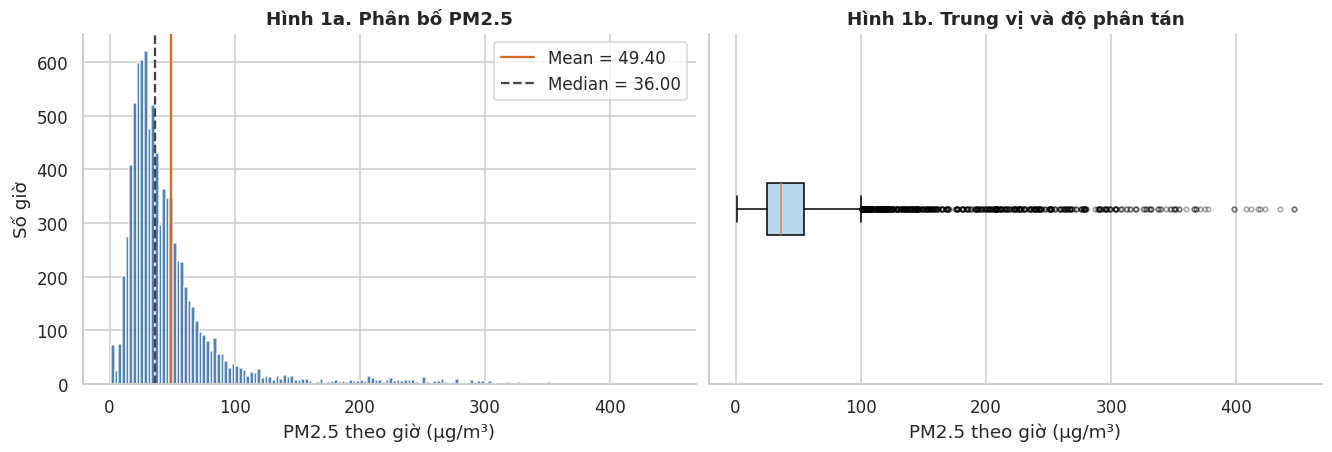

In [4]:
summary = hourly[['PM25', 'AQI']].describe(percentiles=[.25, .5, .75, .9, .95]).T
summary.columns = ['Số giờ', 'Mean', 'Độ lệch chuẩn', 'Min', 'Q1', 'Median', 'Q3', 'P90', 'P95', 'Max']
display(summary.round(2))
pm = hourly['PM25'].dropna()
q1, median, q3 = pm.quantile([.25, .5, .75])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(pm, bins='fd', color=BLUE, alpha=.8, edgecolor='white')
axes[0].axvline(pm.mean(), color=ORANGE, label=f'Mean = {pm.mean():.2f}')
axes[0].axvline(median, color='#444444', linestyle='--', label=f'Median = {median:.2f}')
axes[0].set(xlabel='PM2.5 theo giờ (µg/m³)', ylabel='Số giờ', title='Hình 1a. Phân bố PM2.5')
axes[0].legend()
axes[1].boxplot(pm, vert=False, patch_artist=True, boxprops={'facecolor':'#b8d8ee'},
                flierprops={'markersize':3, 'alpha':.35})
axes[1].set(xlabel='PM2.5 theo giờ (µg/m³)', yticks=[], title='Hình 1b. Trung vị và độ phân tán')
show_figure(fig, '01_distribution')

**Đọc Hình 1:** histogram đếm số giờ trong từng khoảng nồng độ; độ cao không phải nồng độ. Chọn khoảng bằng quy tắc Freedman–Diaconis (`fd`), dựa vào IQR và cỡ mẫu để tránh đặt khoảng hoàn toàn tùy ý. Boxplot có hộp Q1–Q3, đường giữa là median; râu tới quan sát xa nhất còn trong giới hạn 1,5 × IQR tính từ hai đầu hộp. Điểm ngoài râu chưa chắc là dữ liệu lỗi.

**Vì sao dùng:** hai hình kết hợp cho thấy hình dạng, đuôi và mức điển hình. Một cột mean chỉ cho một con số, không cho biết các giờ tập trung ở đâu. Không dùng biểu đồ tròn vì nồng độ là biến liên tục, không phải các phần của một tổng.

**Giới hạn:** độ chi tiết histogram thay đổi theo cách chia khoảng; boxplot không cho biết đỉnh xảy ra ngày nào. Không tự xóa các điểm ngoài râu.

In [5]:
outside_iqr = int(((pm < q1 - 1.5*(q3-q1)) | (pm > q3 + 1.5*(q3-q1))).sum())
display(Markdown(f'**Kết quả Hình 1:** mean **{pm.mean():.2f}**, median **{median:.2f} µg/m³** '
                 f'(chênh {pm.mean()-median:.2f}); P95 **{pm.quantile(.95):.2f}**, max **{pm.max():.2f} µg/m³**. '
                 f'Có **{outside_iqr} giờ** ngoài râu theo quy tắc IQR. '
                 'Các giá trị cao kéo mean lên so với median; dùng cả hai giúp mô tả dữ liệu đầy đủ hơn. '
                 'Đây là mô tả phân bố, chưa xác định nguyên nhân các đỉnh.'))

**Kết quả Hình 1:** mean **49.40**, median **36.00 µg/m³** (chênh 13.40); P95 **129.57**, max **446.00 µg/m³**. Có **650 giờ** ngoài râu theo quy tắc IQR. Các giá trị cao kéo mean lên so với median; dùng cả hai giúp mô tả dữ liệu đầy đủ hơn. Đây là mô tả phân bố, chưa xác định nguyên nhân các đỉnh.

## 4. PM2.5 thay đổi theo ngày thế nào?

Xem toàn kỳ trước, sau đó liệt kê năm ngày cao nhất theo cùng tiêu chí **PM2.5 trung bình ngày đủ giờ**. Đường trung bình trượt 7 ngày lấy ngày hiện tại và 6 ngày liền trước, chỉ hiện khi cả 7 ngày đều hợp lệ; đây là làm mượt để quan sát, không phải dự báo.

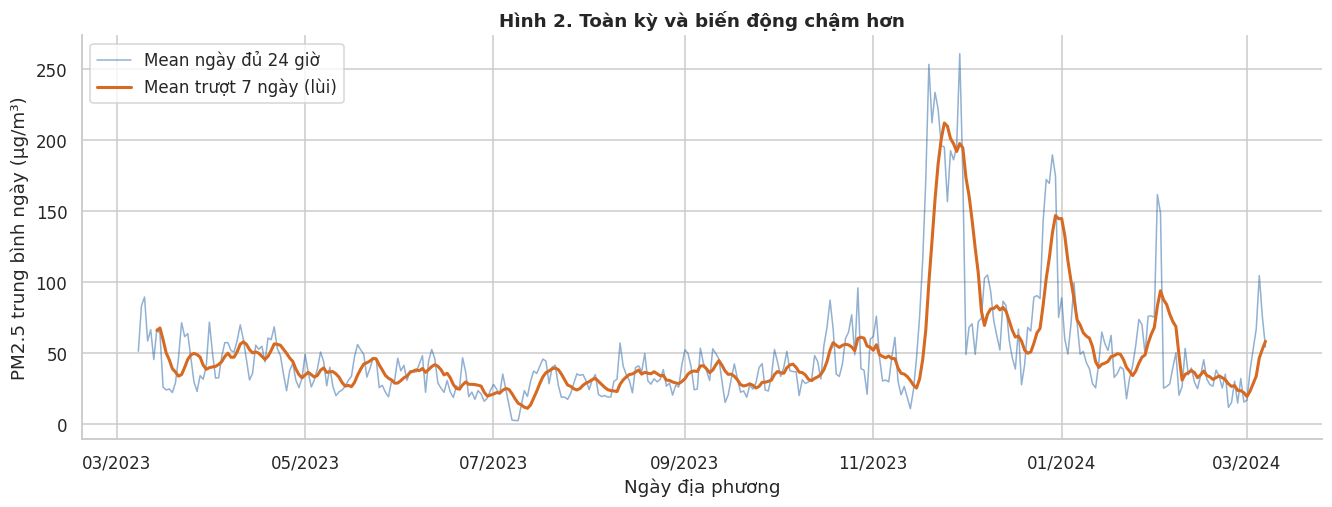

,PM2.5 mean (µg/m³),Số giờ,AQI mean
Local Time,,,
2023-11-29,261.01,24,265.04
2023-11-19,253.47,24,285.08
2023-11-21,233.69,24,256.25
2023-11-22,221.82,24,235.58
2023-11-20,212.24,24,248.17


In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
ax.plot(daily_calendar.index, daily_calendar, color=BLUE, alpha=.5, linewidth=1, label='Mean ngày đủ 24 giờ')
ax.plot(rolling7.index, rolling7, color=ORANGE, linewidth=2, label='Mean trượt 7 ngày (lùi)')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax.set(xlabel='Ngày địa phương', ylabel='PM2.5 trung bình ngày (µg/m³)', title='Hình 2. Toàn kỳ và biến động chậm hơn')
ax.legend(loc='upper left')
show_figure(fig, '02_daily_timeline')
top_days = daily.nlargest(5, 'pm25_mean')[['pm25_mean', 'rows', 'aqi_mean']]
display(top_days.rename(columns={'pm25_mean':'PM2.5 mean (µg/m³)', 'rows':'Số giờ', 'aqi_mean':'AQI mean'}).round(2))

**Đọc Hình 2:** trục ngang là ngày, trục dọc là nồng độ trung bình ngày. Đường xanh nhạt giữ dao động từng ngày; đường cam làm rõ những giai đoạn cao/thấp kéo dài. Khoảng thiếu dữ liệu được để trống.

**Vì sao dùng:** đường thời gian giữ thứ tự quan sát để thấy diễn biến; histogram không giữ thời gian. Không vẽ 8.785 cột giờ cho toàn năm vì quá dày. Việc lấy mean ngày giúp đọc xu hướng dài, nhưng có thể che khuất đỉnh trong ngày nên bài còn có phân tích theo giờ.

**Giới hạn:** đường trượt làm dịu đỉnh và phản ứng trễ. Ngày PM2.5 cao không đồng nghĩa đã biết nguyên nhân; bảng AQI đi kèm chỉ bổ sung bối cảnh.

In [7]:
peak_day = top_days.index[0]
display(Markdown(f'**Kết quả Hình 2:** ngày có PM2.5 mean cao nhất là **{peak_day:%d/%m/%Y}**, '
                 f'**{top_days.iloc[0].pm25_mean:.2f} µg/m³**, từ đủ 24 giờ. '
                 f'Trung bình trên {len(daily)} ngày đầy đủ là **{daily.pm25_mean.mean():.2f} µg/m³**. '
                 'Đây là xếp hạng theo mean ngày, không nhất thiết cùng ngày có đỉnh một giờ cao nhất.'))

**Kết quả Hình 2:** ngày có PM2.5 mean cao nhất là **29/11/2023**, **261.01 µg/m³**, từ đủ 24 giờ. Trung bình trên 366 ngày đầy đủ là **49.40 µg/m³**. Đây là xếp hạng theo mean ngày, không nhất thiết cùng ngày có đỉnh một giờ cao nhất.

### 4.1. Bổ sung góc nhìn AQI

PM2.5 là nồng độ của một loại bụi; AQI là chỉ số do nguồn cung cấp. Vẽ thêm AQI để quan sát diễn biến chỉ số, không dùng nó làm tên khác của PM2.5. Giữ cả AQI theo giờ và mean ngày đủ 24 giá trị AQI để nhìn được đỉnh ngắn lẫn giai đoạn kéo dài.

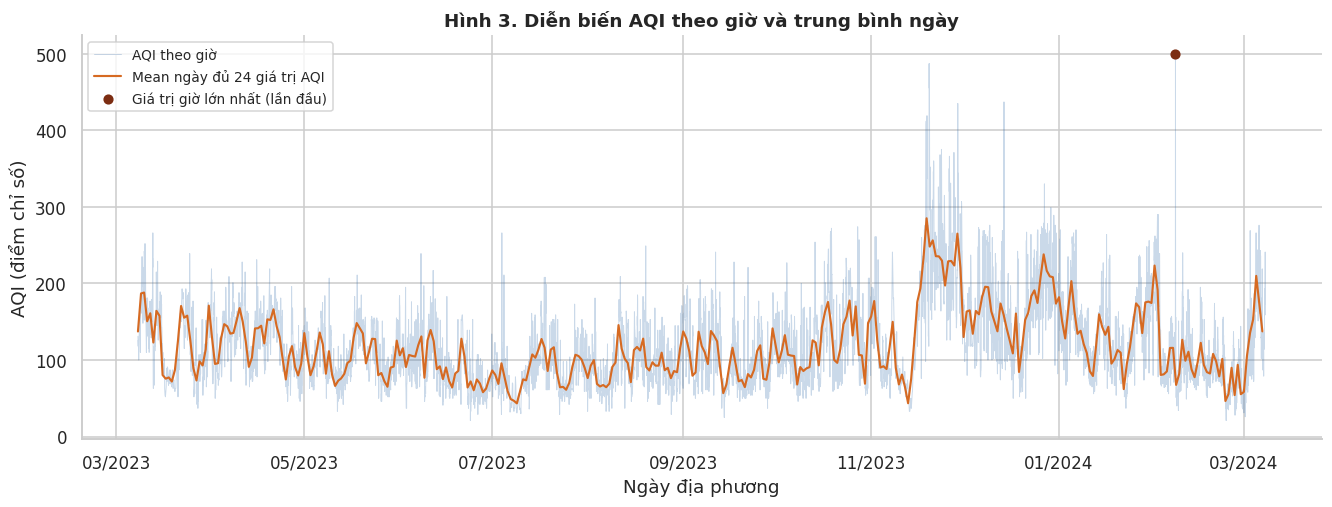

In [8]:
aqi_hourly = hourly['AQI'].reindex(expected_hours)
aqi_complete = daily_audit['rows'].eq(24) & daily_audit['valid_aqi'].eq(24)
aqi_daily = daily_audit['aqi_mean'].where(aqi_complete)
aqi_peak_time = hourly['AQI'].idxmax()
aqi_peak_value = float(hourly['AQI'].max())
aqi_peak_count = int(hourly['AQI'].eq(aqi_peak_value).sum())
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
ax.plot(aqi_hourly.index, aqi_hourly, color=BLUE, alpha=.24, linewidth=.65, label='AQI theo giờ')
ax.plot(aqi_daily.index, aqi_daily, color=ORANGE, linewidth=1.4, label='Mean ngày đủ 24 giá trị AQI')
ax.scatter([aqi_peak_time], [aqi_peak_value], color='#7c2d12', s=32, zorder=4, label='Giá trị giờ lớn nhất (lần đầu)')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax.set(xlabel='Ngày địa phương', ylabel='AQI (điểm chỉ số)', title='Hình 3. Diễn biến AQI theo giờ và trung bình ngày')
ax.legend(loc='upper left', fontsize=9)
show_figure(fig, 'aqi_timeline')

**Đọc Hình 3:** đường xanh nhạt là AQI từng giờ; đường cam là trung bình của ngày có đủ 24 mốc giờ và 24 AQI hợp lệ. Điểm nâu đánh dấu lần đầu đạt giá trị giờ cao nhất. Trục đứng là điểm AQI, không phải µg/m³. Ngày thiếu giờ không có mean ngày; các mốc giờ vắng được để trống.

**Vì sao dùng:** đường thời gian cho biết khi nào chỉ số tăng và tăng trong bao lâu. Một bảng mean/max không giữ thứ tự thời gian; chỉ vẽ mean ngày có thể che đỉnh giờ. Không dùng chung trục đứng với PM2.5 vì hai đại lượng khác đơn vị và ý nghĩa.

**Giới hạn:** mean AQI ngày ở đây là thống kê mô tả của các chỉ số giờ, không phải AQI ngày được tính lại theo quy chuẩn. Bài không tự gắn ngưỡng sức khỏe khi chưa xác minh hệ AQI và quy tắc nguồn. Hai biểu đồ có diễn biến giống nhau cũng chưa chứng minh chất nào quyết định AQI.

In [9]:
display(Markdown(f'**Kết quả Hình 3:** AQI theo giờ có mean **{hourly.AQI.mean():.2f}**, '
                 f'median **{hourly.AQI.median():.2f}**; giá trị lớn nhất **{aqi_peak_value:.0f}**, '
                 f'xuất hiện lần đầu lúc **{aqi_peak_time:%H:%M ngày %d/%m/%Y}** '
                 f'(tổng {aqi_peak_count} giờ đồng mức lớn nhất). '
                 f'Có **{int(aqi_complete.sum())} ngày** đủ điều kiện tính mean AQI. '
                 f'Ngày PM2.5 mean cao nhất ở Hình 2 là **{peak_day:%d/%m/%Y}**: '
                 'cực đại AQI giờ và cực đại PM2.5 mean ngày khác cả đại lượng lẫn thang thời gian, '
                 'nên không được coi là cùng một tiêu chí xếp hạng.'))

**Kết quả Hình 3:** AQI theo giờ có mean **117.63**, median **104.00**; giá trị lớn nhất **500**, xuất hiện lần đầu lúc **19:00 ngày 07/02/2024** (tổng 1 giờ đồng mức lớn nhất). Có **366 ngày** đủ điều kiện tính mean AQI. Ngày PM2.5 mean cao nhất ở Hình 2 là **29/11/2023**: cực đại AQI giờ và cực đại PM2.5 mean ngày khác cả đại lượng lẫn thang thời gian, nên không được coi là cùng một tiêu chí xếp hạng.

## 5. So sánh tháng và mùa

Mỗi mẫu ở phần này là **PM2.5 trung bình của một ngày đủ giờ**. Mean và median theo tháng đều tính từ các mẫu ngày đó. Tháng được phân biệt bằng năm–tháng, không gộp tháng 3 của hai năm.

Quy ước mùa của bài: xuân tháng 2–4, hạ 5–7, thu 8–10, đông 11–1. Giữ quy ước để đối chiếu bài tham khảo, không coi là cách phân mùa duy nhất. Chỉ có khoảng một năm dữ liệu, nên không diễn giải thành xu hướng nhiều năm.

,Ngày đủ giờ,Mean,Median,Ngày lịch,Bao phủ (%),Phạm vi
2023-03,24,48.74,46.44,31,77.42,Một phần / không đủ ngày
2023-04,30,46.74,49.21,30,100.00,Trọn tháng
2023-05,31,35.36,32.97,31,100.00,Trọn tháng
2023-06,30,30.64,27.72,30,100.00,Trọn tháng
2023-07,31,26.42,27.79,31,100.00,Trọn tháng
2023-08,31,31.00,30.29,31,100.00,Trọn tháng
2023-09,30,34.47,31.88,30,100.00,Trọn tháng
2023-10,31,46.24,39.71,31,100.00,Trọn tháng
2023-11,30,113.41,75.72,30,100.00,Trọn tháng
2023-12,31,85.39,72.81,31,100.00,Trọn tháng


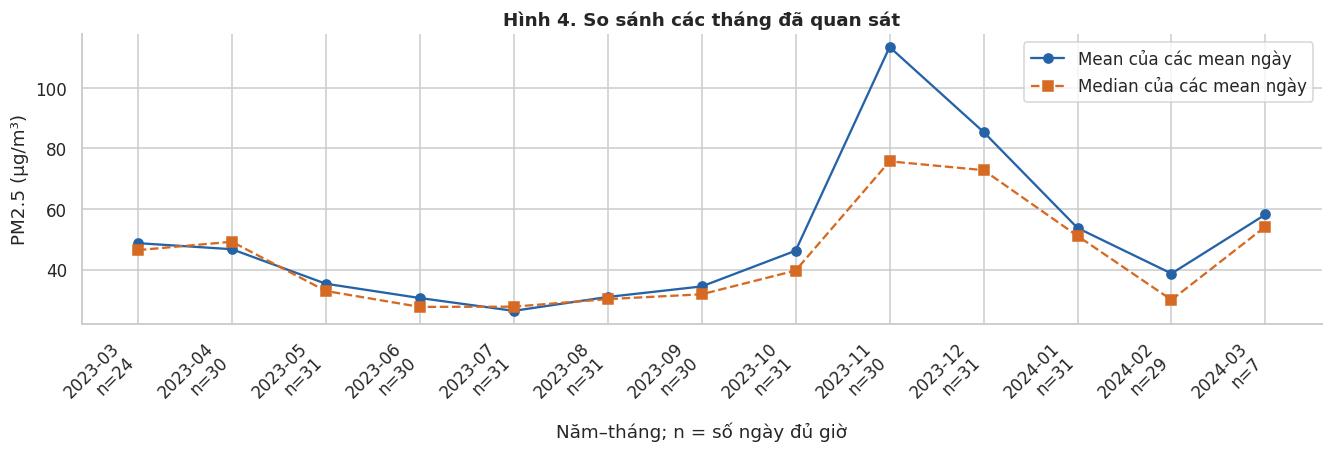

In [10]:
month_index = pd.period_range(hourly.index.min().to_period('M'), hourly.index.max().to_period('M'), freq='M')
monthly = daily.groupby(daily.index.to_period('M'))['pm25_mean'].agg(n='count', mean='mean', median='median')
monthly = monthly.reindex(month_index)
monthly['n'] = monthly['n'].fillna(0).astype(int)
monthly['days_in_month'] = month_index.days_in_month
monthly['coverage_percent'] = 100 * monthly['n'] / monthly['days_in_month']
monthly['coverage'] = np.where(monthly['n'].eq(monthly['days_in_month']), 'Trọn tháng', 'Một phần / không đủ ngày')
display(monthly.rename(columns={'n':'Ngày đủ giờ', 'mean':'Mean', 'median':'Median',
                              'days_in_month':'Ngày lịch', 'coverage_percent':'Bao phủ (%)', 'coverage':'Phạm vi'}).round(2))
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
x = np.arange(len(monthly))
ax.plot(x, monthly['mean'], 'o-', label='Mean của các mean ngày', color=BLUE)
ax.plot(x, monthly['median'], 's--', label='Median của các mean ngày', color=ORANGE)
ax.set_xticks(x, [f'{m}{chr(10)}n={n}' for m,n in zip(monthly.index, monthly['n'])], rotation=45, ha='right')
ax.set(xlabel='Năm–tháng; n = số ngày đủ giờ', ylabel='PM2.5 (µg/m³)', title='Hình 4. So sánh các tháng đã quan sát')
ax.legend()
show_figure(fig, '03_monthly')

**Đọc Hình 4:** mỗi vị trí là một năm–tháng; hai đường là mean và median của các mean ngày. `n` dưới nhãn là số ngày đủ giờ. Một tháng không có ngày hợp lệ sẽ không có điểm hay đường nối qua nó.

**Vì sao dùng:** đường theo thứ tự tháng giúp thấy diễn biến mùa và so sánh mean/median. Một đường mean duy nhất có thể che ảnh hưởng của vài ngày tăng cao. Chưa dùng mô hình xu hướng vì mục đích ở đây là mô tả một giai đoạn ngắn.

**Giới hạn:** tháng đầu và cuối có thể không trọn vẹn. Mean của phần tháng được quan sát không đại diện chắc chắn cho cả tháng; các đường nối chỉ giúp đọc thứ tự, không nội suy các ngày chưa đo.

**Kết quả Hình 4:** trong các tháng có ngày hợp lệ, mean cao nhất ở **2023-11** (**113.41 µg/m³**, n=30); thấp nhất ở **2023-07** (**26.42 µg/m³**, n=31). Bảng bao phủ phía trên cần được đọc cùng xếp hạng này.

,n,mean,median,q1,q3
Season,,,,,
Xuân,90,45.58,40.30,29.44,56.78
Hạ,92,30.81,30.08,22.50,39.27
Thu,92,37.27,33.45,27.27,42.81
Đông,92,83.86,66.15,43.03,91.15


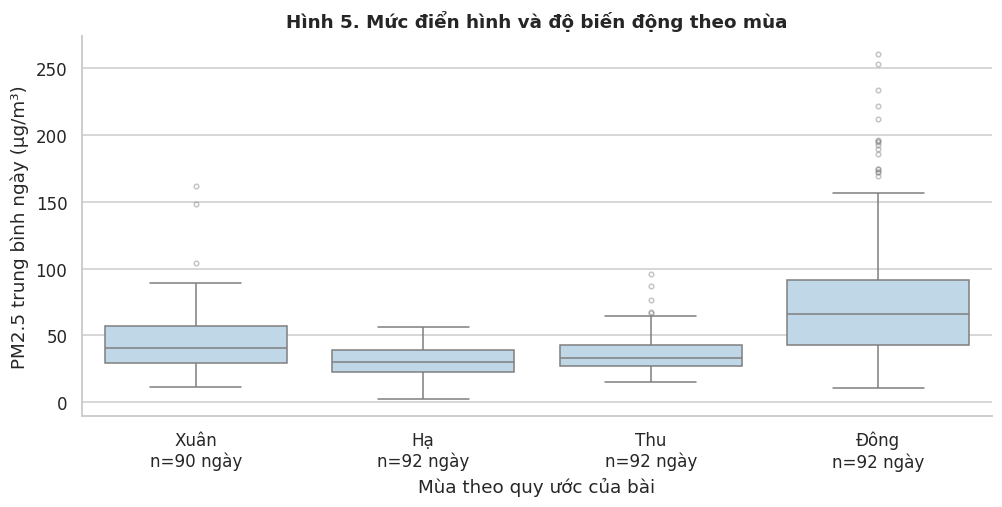

In [11]:
high_month, low_month = monthly['mean'].idxmax(), monthly['mean'].idxmin()
display(Markdown(f'**Kết quả Hình 4:** trong các tháng có ngày hợp lệ, mean cao nhất ở **{high_month}** '
                 f'(**{monthly.loc[high_month, "mean"]:.2f} µg/m³**, n={monthly.loc[high_month, "n"]}); '
                 f'thấp nhất ở **{low_month}** (**{monthly.loc[low_month, "mean"]:.2f} µg/m³**, '
                 f'n={monthly.loc[low_month, "n"]}). Bảng bao phủ phía trên cần được đọc cùng xếp hạng này.'))
season_daily = daily.groupby('Season')['pm25_mean'].agg(n='count', mean='mean', median='median',
                                                       q1=lambda s:s.quantile(.25), q3=lambda s:s.quantile(.75)).reindex(SEASONS)
display(season_daily.round(2))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
sns.boxplot(data=daily, x='Season', y='pm25_mean', order=SEASONS, color='#b8d8ee', ax=ax,
            flierprops={'markersize':3, 'alpha':.45})
ax.set_xticks(range(4), [f'{s}{chr(10)}n={int(season_daily.loc[s,"n"])} ngày' for s in SEASONS])
ax.set(xlabel='Mùa theo quy ước của bài', ylabel='PM2.5 trung bình ngày (µg/m³)', title='Hình 5. Mức điển hình và độ biến động theo mùa')
show_figure(fig, '04_seasons')

**Đọc Hình 5:** mỗi hộp gom các mean ngày của một mùa. Đường giữa là median, hộp Q1–Q3 chứa 50% giá trị giữa, râu theo 1,5 × IQR; điểm ngoài râu là ngày khác biệt về thống kê, không tự động là lỗi.

**Vì sao dùng:** boxplot cho thấy mức điển hình, độ phân tán và sự chồng lấn giữa mùa. Bốn cột mean chỉ so sánh bốn con số, không cho biết biến động trong mỗi mùa. Hộp rộng theo trục đứng là biến động lớn, không phải nhiều ngày hơn; số ngày được ghi bằng `n`.

**Giới hạn:** nhóm tháng của mỗi mùa là quy ước, số ngày khác nhau; đây chưa phải kiểm định khác biệt hay bằng chứng mùa gây ra ô nhiễm.

In [12]:
high_season, low_season = season_daily['mean'].idxmax(), season_daily['mean'].idxmin()
display(Markdown(f'**Kết quả Hình 5:** mean ngày theo mùa cao nhất ở **{high_season}** '
                 f'(**{season_daily.loc[high_season,"mean"]:.2f} µg/m³**), thấp nhất ở **{low_season}** '
                 f'(**{season_daily.loc[low_season,"mean"]:.2f} µg/m³**). '
                 f'Median tương ứng là **{season_daily.loc[high_season,"median"]:.2f}** và '
                 f'**{season_daily.loc[low_season,"median"]:.2f} µg/m³**. '
                 'So sánh cả median và hộp phân bố giúp tránh chỉ dựa vào một vài ngày rất cao.'))

**Kết quả Hình 5:** mean ngày theo mùa cao nhất ở **Đông** (**83.86 µg/m³**), thấp nhất ở **Hạ** (**30.81 µg/m³**). Median tương ứng là **66.15** và **30.08 µg/m³**. So sánh cả median và hộp phân bố giúp tránh chỉ dựa vào một vài ngày rất cao.

## 6. Giờ nào thường cao/thấp? Có giống giữa các tháng không?

Gom các quan sát theo giờ địa phương 0–23. Mỗi nhóm gồm cùng một giờ của nhiều ngày, không phải 24 điểm của một ngày duy nhất. Mean và median mô tả hai cách nhìn về mức điển hình; dải Q1–Q3 mô tả độ biến thiên của các quan sát.

,n,mean,median,q1,q3
Local Time,,,,,
0,367,48.20,34.00,22.66,55.00
1,366,45.94,34.00,22.00,52.93
2,366,48.65,34.75,23.75,52.83
3,366,52.53,35.00,23.84,56.00
4,366,49.33,34.60,24.00,55.00
5,366,51.40,36.66,24.00,54.75
6,366,52.78,35.50,24.00,55.67
7,366,51.86,38.00,26.00,55.00
8,366,54.40,38.00,25.08,56.69


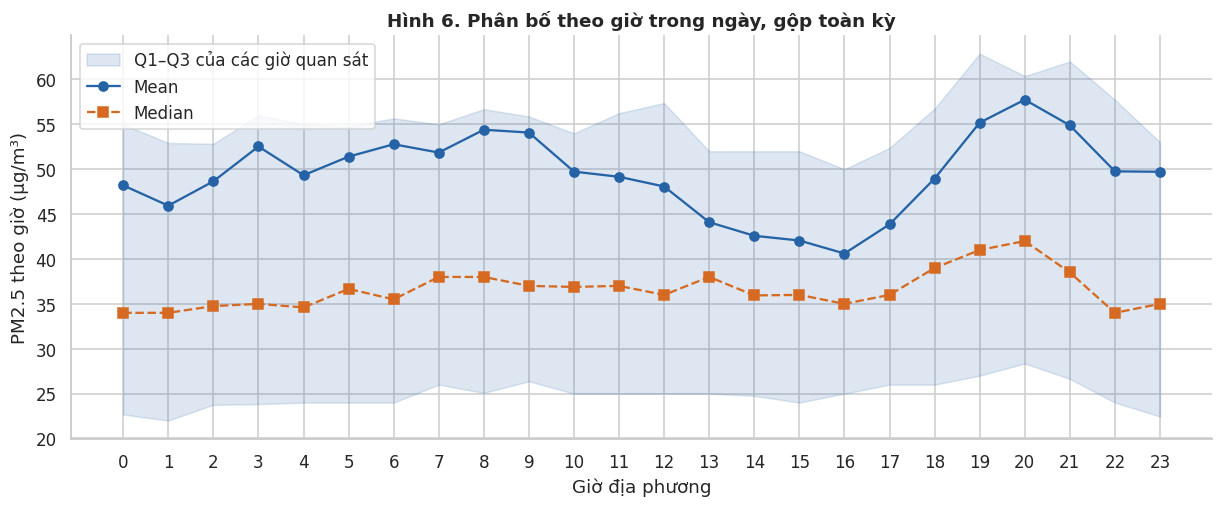

In [13]:
by_hour = hourly.groupby(hourly.index.hour)['PM25'].agg(n='count', mean='mean', median='median',
                                                       q1=lambda s:s.quantile(.25), q3=lambda s:s.quantile(.75))
display(by_hour.round(2))
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
ax.fill_between(by_hour.index, by_hour.q1, by_hour.q3, color=BLUE, alpha=.15, label='Q1–Q3 của các giờ quan sát')
ax.plot(by_hour.index, by_hour['mean'], 'o-', color=BLUE, label='Mean')
ax.plot(by_hour.index, by_hour['median'], 's--', color=ORANGE, label='Median')
ax.set(xticks=range(24), xlabel='Giờ địa phương', ylabel='PM2.5 theo giờ (µg/m³)', title='Hình 6. Phân bố theo giờ trong ngày, gộp toàn kỳ')
ax.legend(loc='upper left')
show_figure(fig, '05_hour_profile')

**Đọc Hình 6:** đường xanh là mean, đường cam là median; dải nhạt là Q1–Q3 ở từng giờ. Dải chứa 50% giá trị giữa, **không phải khoảng tin cậy của mean**. Bảng cho biết cỡ mẫu, vì các giờ có thể không cùng số quan sát.

**Vì sao dùng:** hai đường giúp kiểm tra giờ cao theo mean có còn cao khi dùng median; dải mô tả sự biến thiên mà biểu đồ cột mean bỏ qua. Dùng đường vì các giờ có thứ tự, không dùng histogram vì câu hỏi hiện tại là so sánh giờ, không phải phân bố nồng độ.

**Giới hạn:** gộp cả năm có thể che khác biệt giữa các giai đoạn; giờ có mean cao nhất không phải lúc cao nhất trong mọi ngày. Dữ liệu không có lưu lượng xe để quy nguyên nhân cho giao thông.

**Kết quả Hình 6:** mean cao nhất lúc **20h (57.75)**, thấp nhất lúc **16h (40.61 µg/m³)**; chênh **17.14 µg/m³**. Giờ có median cao nhất là **20h**. Mỗi giờ có **366–367 quan sát hợp lệ**.

,Ít mẫu nhất/ô,Nhiều mẫu nhất/ô
2023-03,24,24
2023-04,30,30
2023-05,31,31
2023-06,30,30
2023-07,31,31
2023-08,31,31
2023-09,30,30
2023-10,31,31
2023-11,30,30
2023-12,31,31


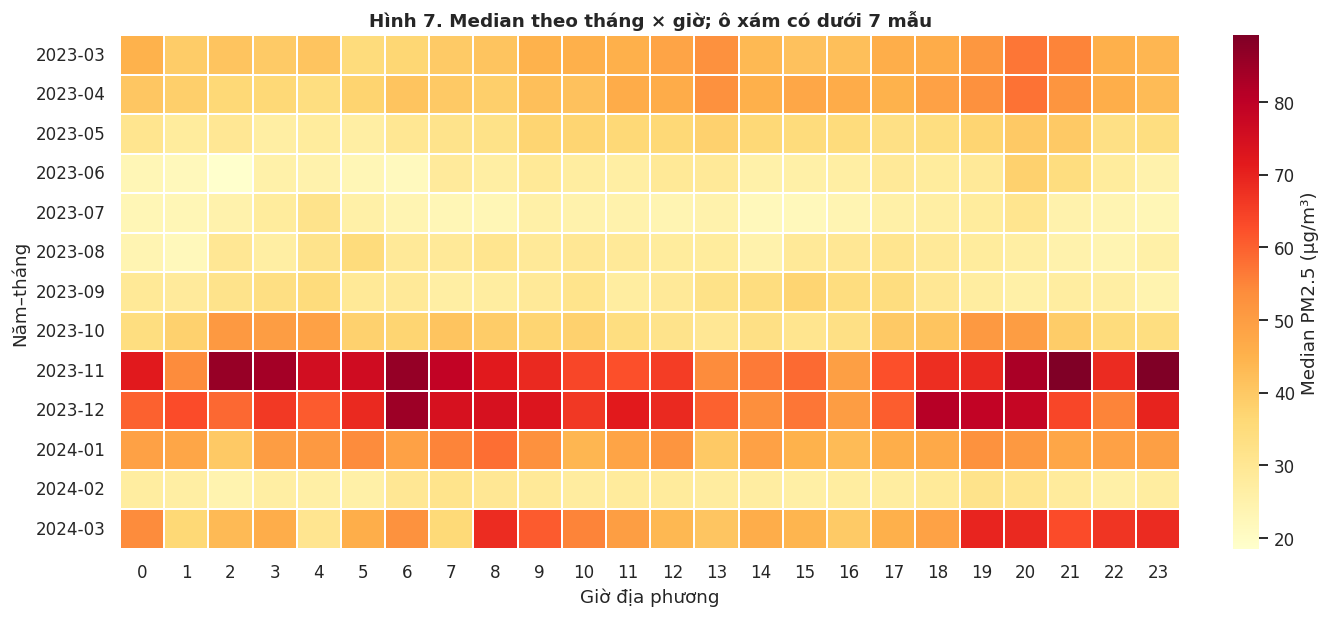

In [14]:
peak_hour, low_hour = int(by_hour['mean'].idxmax()), int(by_hour['mean'].idxmin())
display(Markdown(f'**Kết quả Hình 6:** mean cao nhất lúc **{peak_hour}h ({by_hour.loc[peak_hour,"mean"]:.2f})**, '
                 f'thấp nhất lúc **{low_hour}h ({by_hour.loc[low_hour,"mean"]:.2f} µg/m³)**; '
                 f'chênh **{by_hour.loc[peak_hour,"mean"]-by_hour.loc[low_hour,"mean"]:.2f} µg/m³**. '
                 f'Giờ có median cao nhất là **{int(by_hour["median"].idxmax())}h**. '
                 f'Mỗi giờ có **{int(by_hour.n.min())}–{int(by_hour.n.max())} quan sát hợp lệ**.'))
grid_source = hourly.assign(Month=hourly.index.to_period('M').astype(str), Hour=hourly.index.hour)
heat_median = grid_source.pivot_table(index='Month', columns='Hour', values='PM25', aggfunc='median').reindex(
    index=month_index.astype(str), columns=range(24))
heat_count = grid_source.pivot_table(index='Month', columns='Hour', values='PM25', aggfunc='count').reindex(
    index=month_index.astype(str), columns=range(24)).fillna(0).astype(int)
display(pd.DataFrame({'Ít mẫu nhất/ô':heat_count.min(axis=1), 'Nhiều mẫu nhất/ô':heat_count.max(axis=1)}))
# Dưới 7 quan sát/ô: một quy tắc hiển thị để tránh đọc mẫu quá ít như quy luật tháng.
MIN_CELL_SAMPLES = 7
heat_visible = heat_median.where(heat_count.ge(MIN_CELL_SAMPLES))
fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
ax.set_facecolor('#e5e7eb')
sns.heatmap(heat_visible, cmap='YlOrRd', ax=ax, linewidths=.15,
            cbar_kws={'label':'Median PM2.5 (µg/m³)'})
ax.set(xlabel='Giờ địa phương', ylabel='Năm–tháng', title='Hình 7. Median theo tháng × giờ; ô xám có dưới 7 mẫu')
show_figure(fig, '06_month_hour_heatmap')

**Đọc Hình 7:** mỗi ô gom cùng giờ trong một năm–tháng. Màu đậm hơn theo thang màu biểu thị median PM2.5 cao hơn, không phải nhiều giờ hơn. Mọi ô dùng chung một thang màu. Ô xám có dưới 7 quan sát hợp lệ, gồm cả ô không có dữ liệu; 7 là lựa chọn hiển thị của bài, không bảo đảm độ tin cậy thống kê.

**Vì sao dùng:** heatmap giúp xem đồng thời tháng và giờ, để kiểm tra đường gộp toàn kỳ ở Hình 6 có che khác biệt không. Nếu vẽ một đường cho mỗi tháng, nhiều đường chồng lên nhau sẽ khó đọc. Dùng median để giảm ảnh hưởng của một số giờ cực cao; không có nghĩa mean không còn hữu ích.

**Giới hạn:** không thể đọc chi tiết từng ngày từ một ô; nhóm tháng đầu/cuối có bao phủ khác nhau. Màu khác nhau chưa phải bằng chứng một nguyên nhân cụ thể.

In [15]:
month_peaks = heat_visible.dropna(how='all').idxmax(axis=1).astype(int)
display(month_peaks.rename('Giờ có median cao nhất trong tháng').to_frame())
display(Markdown(f'**Kết quả Hình 7:** giờ có median cao nhất nằm ở **{month_peaks.nunique()} giờ khác nhau** '
                 f'trong **{len(month_peaks)} tháng đủ điều kiện hiển thị**. '
                 'Bảng trên cho thấy vị trí đỉnh theo tháng; không nên suy từ một đỉnh gộp cả năm '
                 'rằng giờ đó luôn cao nhất. Nếu có nhiều giờ đồng hạng, bảng chọn giờ đầu theo thứ tự.'))

,Giờ có median cao nhất trong tháng
2023-03,20
2023-04,20
2023-05,20
2023-06,20
2023-07,4
2023-08,5
2023-09,15
2023-10,2
2023-11,21
2023-12,6


**Kết quả Hình 7:** giờ có median cao nhất nằm ở **9 giờ khác nhau** trong **13 tháng đủ điều kiện hiển thị**. Bảng trên cho thấy vị trí đỉnh theo tháng; không nên suy từ một đỉnh gộp cả năm rằng giờ đó luôn cao nhất. Nếu có nhiều giờ đồng hạng, bảng chọn giờ đầu theo thứ tự.

## 7. PM2.5 liên hệ thế nào với thời tiết?

### Bối cảnh: thời tiết của các mùa trong mẫu

Trước khi đọc tương quan, cần biết các nhóm mùa có điều kiện thời tiết khác nhau thế nào. Bảng dưới dùng các **giờ hợp lệ** của từng biến; bảng số mẫu đi kèm giúp thấy bao phủ. Mùa xuân gộp các phần tháng 3–4/2023 và 2–3/2024 theo quy ước của bài, không phải một mùa xuân liên tục được quan sát trọn vẹn.

Chọn bảng vì cần đọc chính xác nhiều biến khác đơn vị, không đưa chúng lên một trục chung. Với mưa, dùng tỷ lệ giờ có mưa và median lượng mưa trong các giờ có mưa để phân biệt **tần suất** và **cường độ của giờ mưa**. Không chỉ báo mean lượng mưa vì nhiều số 0 làm con số khó hình dung; không so tổng mưa giữa các mùa mà bỏ qua số giờ bao phủ khác nhau.

In [16]:
season_weather = hourly.groupby('Season')[WEATHER[:4]].mean().reindex(SEASONS)
season_weather.columns = [f'{LABELS[w]} — mean giờ' for w in WEATHER[:4]]
weather_counts = hourly.groupby('Season')[WEATHER].count().reindex(SEASONS)
wet_hours = hourly['Precipitation'].gt(0).where(hourly['Precipitation'].notna())
rain_frequency = wet_hours.groupby(hourly['Season']).mean().reindex(SEASONS).astype(float) * 100
wet_rain_median = hourly.loc[hourly['Precipitation'].gt(0)].groupby('Season')['Precipitation'].median().reindex(SEASONS)
season_weather['Giờ có mưa (%)'] = rain_frequency
season_weather['Median mưa khi > 0 (mm/giờ quan sát)'] = wet_rain_median
display(season_weather.round(2))
display(weather_counts.rename(columns=LABELS).rename_axis('Số giờ hợp lệ / mùa'))
wettest_season = rain_frequency.idxmax()
dryest_season = rain_frequency.idxmin()
display(Markdown(f'**Đọc bảng:** tỷ lệ giờ có mưa cao nhất ở **{wettest_season}: '
                 f'{rain_frequency.loc[wettest_season]:.1f}%**, thấp nhất ở **{dryest_season}: '
                 f'{rain_frequency.loc[dryest_season]:.1f}%**. '
                 f'Mean nhiệt độ ở Đông **{season_weather.loc["Đông", season_weather.columns[0]]:.2f} °C**, '
                 f'ở Hạ **{season_weather.loc["Hạ", season_weather.columns[0]]:.2f} °C**. '
                 'Đây là bối cảnh của các giờ có trong bộ dữ liệu, không phải thống kê khí hậu nhiều năm '
                 'và chưa chứng minh các điều kiện này gây ra khác biệt PM2.5. '
                 'Nếu một mùa không có giờ mưa, median mưa khi > 0 sẽ để thiếu, không thay bằng 0.'))

,Nhiệt độ (°C) — mean giờ,Độ ẩm (%) — mean giờ,Áp suất (hPa) — mean giờ,Gió (m/s) — mean giờ,Giờ có mưa (%),Median mưa khi > 0 (mm/giờ quan sát)
Season,,,,,,
Xuân,22.23,82.02,1011.70,1.83,12.82,0.50
Hạ,29.97,77.08,1003.49,1.65,27.04,0.75
Thu,28.43,77.30,1006.91,1.46,29.21,1.00
Đông,20.44,75.85,1017.96,1.49,9.74,0.50


,Nhiệt độ (°C),Độ ẩm (%),Áp suất (hPa),Gió (m/s),Mưa (mm)
Số giờ hợp lệ / mùa,,,,,
Xuân,2161,2161,2161,2161,2161
Hạ,2208,2208,2208,2208,2208
Thu,2208,2208,2208,2208,2208
Đông,2208,2208,2208,2208,2208


**Đọc bảng:** tỷ lệ giờ có mưa cao nhất ở **Thu: 29.2%**, thấp nhất ở **Đông: 9.7%**. Mean nhiệt độ ở Đông **20.44 °C**, ở Hạ **29.97 °C**. Đây là bối cảnh của các giờ có trong bộ dữ liệu, không phải thống kê khí hậu nhiều năm và chưa chứng minh các điều kiện này gây ra khác biệt PM2.5. Nếu một mùa không có giờ mưa, median mưa khi > 0 sẽ để thiếu, không thay bằng 0.

### 7.1. Pearson và Spearman

**Pearson** đo liên hệ tuyến tính; **Spearman** đo liên hệ đơn điệu dựa trên thứ hạng. Giá trị trong −1 đến +1: dương là xu hướng cùng chiều, âm là ngược chiều; gần 0 không loại trừ mọi quan hệ phi tuyến.

Chọn Spearman cho hình chính để có thêm góc nhìn khi PM2.5 và mưa lệch, đồng thời đối chiếu Pearson. Spearman không luôn tốt hơn và không giải quyết nhiễu do mùa. Mọi cặp dưới đây ghép **cùng giờ**, không ghép nồng độ ngày với thời tiết giờ. Không dùng p-value như thể các giờ hoàn toàn độc lập.

,Pearson,Spearman,Số cặp giờ
Temperature,-0.254,-0.246,8785
Relative Humidity,-0.007,-0.055,8785
Pressure,0.297,0.264,8785
Wind Speed,-0.155,-0.150,8785
Precipitation,-0.095,-0.197,8785


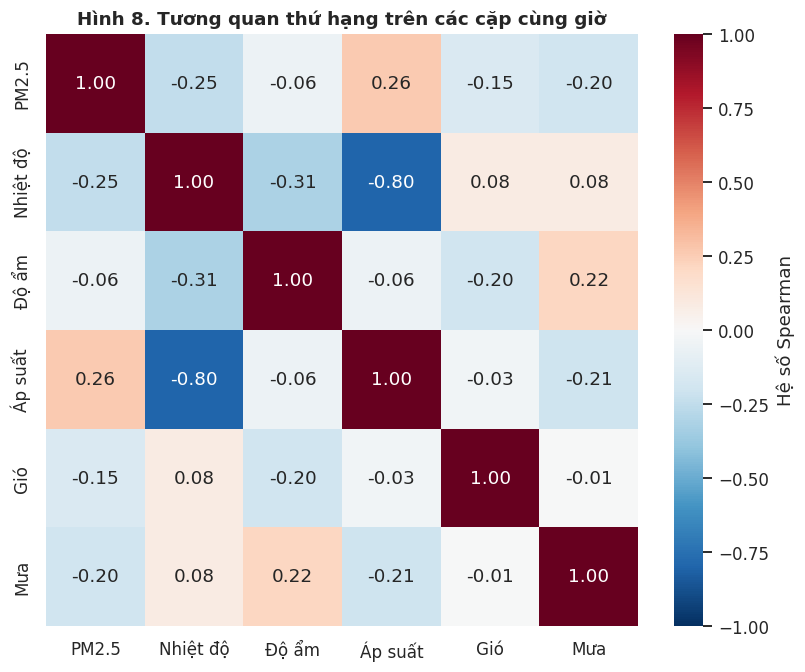

In [17]:
corr_columns = ['PM25'] + WEATHER
spearman = hourly[corr_columns].corr(method='spearman')
pearson = hourly[corr_columns].corr(method='pearson')
weather_corr = pd.DataFrame({
    'Pearson': pearson.loc[WEATHER, 'PM25'], 'Spearman':spearman.loc[WEATHER, 'PM25'],
    'Số cặp giờ': [len(hourly[['PM25', w]].dropna()) for w in WEATHER],
})
display(weather_corr.round(3))
short_labels = ['PM2.5', 'Nhiệt độ', 'Độ ẩm', 'Áp suất', 'Gió', 'Mưa']
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
sns.heatmap(spearman, vmin=-1, vmax=1, center=0, cmap='RdBu_r', annot=True, fmt='.2f', square=True,
            xticklabels=short_labels, yticklabels=short_labels, ax=ax, cbar_kws={'label':'Hệ số Spearman'})
ax.set_title('Hình 8. Tương quan thứ hạng trên các cặp cùng giờ')
show_figure(fig, '07_correlations')

**Đọc Hình 8:** mỗi ô là hệ số Spearman giữa hai biến; thang màu cố định −1 đến +1, đường chéo bằng 1 vì biến so với chính nó. Các ô PM2.5–thời tiết trả lời câu hỏi chính; các ô thời tiết–thời tiết nhắc rằng những yếu tố này cũng liên hệ với nhau. Bảng cho biết số cặp hợp lệ của từng biến với PM2.5; ma trận dùng các cặp không thiếu tương ứng.

**Vì sao dùng:** heatmap tóm tắt nhiều cặp trong cùng hình. Bảng Pearson bổ sung kiểm tra xem liên hệ tuyến tính và thứ hạng có khác nhau không. Không chỉ chọn hệ số lớn nhất rồi diễn giải nguyên nhân; tương quan không giữ hình dạng đám mây điểm nên cần xem tiếp hexbin.

**Giới hạn:** hệ số chung có thể chịu ảnh hưởng của mùa, các giá trị trùng hạng (mưa bằng 0) và sự phụ thuộc thời gian; nó chưa mô tả một tác động độc lập hay quan hệ nhân quả.

In [18]:
strongest = weather_corr['Spearman'].abs().idxmax()
display(Markdown(f'**Kết quả Hình 8:** trong các biến đã chọn, **{LABELS[strongest]}** có '
                 f'|Spearman| với PM2.5 lớn nhất: **{weather_corr.loc[strongest,"Spearman"]:+.3f}**, '
                 f'Pearson tương ứng **{weather_corr.loc[strongest,"Pearson"]:+.3f}**. '
                 'Đây là xếp hạng mức liên hệ trong mẫu, không phải xếp hạng nguyên nhân gây ô nhiễm.'))

**Kết quả Hình 8:** trong các biến đã chọn, **Áp suất (hPa)** có |Spearman| với PM2.5 lớn nhất: **+0.264**, Pearson tương ứng **+0.297**. Đây là xếp hạng mức liên hệ trong mẫu, không phải xếp hạng nguyên nhân gây ô nhiễm.

### 7.2. Hình dạng và mật độ của các cặp quan sát

Dùng hexbin cho bốn biến thời tiết liên tục. Lượng mưa được phân tích riêng vì có nhiều giá trị bằng 0.

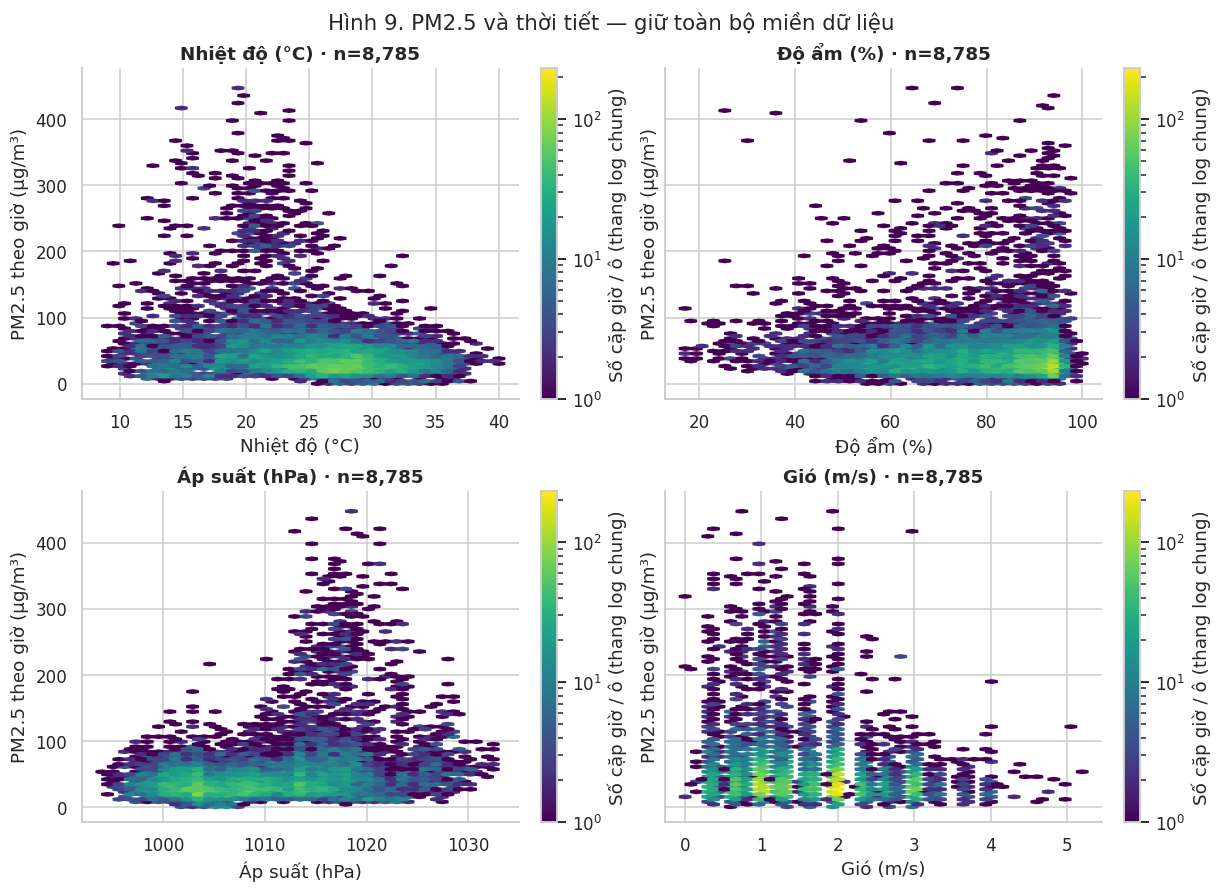

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True, constrained_layout=True)
hexbin_specs, hexbin_artists, dense_rows = {}, [], []
for ax, weather in zip(axes.flat, WEATHER[:4]):
    pair = hourly[[weather, 'PM25']].dropna()
    # Cố định cùng lưới cho hình toàn miền và hình phóng to bên dưới.
    spec = {'gridsize':(35, 60), 'mincnt':1,
            'extent':(float(pair[weather].min()), float(pair[weather].max()), 0, float(pm.max()*1.02))}
    hexbin_specs[weather] = spec
    artist = ax.hexbin(pair[weather], pair['PM25'], cmap='viridis', **spec)
    hexbin_artists.append(artist)
    counts = artist.get_array()
    center = artist.get_offsets()[int(np.argmax(counts))]
    dense_rows.append({'Biến':LABELS[weather], 'Tâm ô — thời tiết':float(center[0]),
                       'Tâm ô — PM2.5 (µg/m³)':float(center[1]), 'Số cặp trong ô':int(counts.max())})
    ax.set(xlabel=LABELS[weather], ylabel='PM2.5 theo giờ (µg/m³)', title=f'{LABELS[weather]} · n={len(pair):,}')
hexbin_norm = LogNorm(vmin=1, vmax=max(float(a.get_array().max()) for a in hexbin_artists))
for ax, artist in zip(axes.flat, hexbin_artists):
    artist.set_norm(hexbin_norm)
    fig.colorbar(artist, ax=ax, label='Số cặp giờ / ô (thang log chung)')
fig.suptitle('Hình 9. PM2.5 và thời tiết — giữ toàn bộ miền dữ liệu', fontsize=14)
show_figure(fig, '08_weather_hexbin')
dense_hexbin = pd.DataFrame(dense_rows).set_index('Biến')

**Đọc Hình 9:** trục x là thời tiết, trục y là nồng độ PM2.5. Một lục giác gom các cặp gần nhau; màu sáng hơn là **nhiều cặp giờ**, không phải PM2.5 cao hơn. Thanh màu đếm giờ theo thang log: các mức 1, 10, 100 là số cặp, không phải nồng độ. Bốn panel dùng chung thang màu số đếm và cùng thang PM2.5; đơn vị trục x được ghi riêng.

**Vì sao dùng:** scatter hàng nghìn điểm dễ chồng lấp, còn một hệ số tương quan không cho biết mật độ và hình dạng. Hexbin giữ dữ liệu rồi gom ô để nhìn vùng tập trung. Hình toàn miền vẫn giữ các đỉnh cao; không cắt chúng chỉ để làm hình đẹp.

**Kết quả và cách kiểm chứng:** bảng tâm ô đông nhất bên dưới định vị vùng tập trung cụ thể. Đó là tâm của một ô chia khoảng, không phải một quan sát thật hay trung bình toàn mẫu; nếu đồng hạng thì chọn ô đầu. Lưới được chọn cố định cho bài; đổi kích thước ô có thể đổi vị trí ô đông nhất. Hình 10 phóng to cùng lưới để đọc vùng thấp rõ hơn.

**Giới hạn:** dù dùng cùng màu đếm, các biến có đơn vị và độ rộng ô x khác nhau, nên không xếp hạng “biến quan trọng hơn” từ độ sáng. Hình chưa loại ảnh hưởng mùa, không phải đường hồi quy và không chứng minh nhân quả.

In [20]:
display(Markdown('**Số liệu đi kèm Hình 9:** ' + '; '.join(
    f'{LABELS[w]}: Pearson {weather_corr.loc[w,"Pearson"]:+.3f}, Spearman {weather_corr.loc[w,"Spearman"]:+.3f}'
    for w in WEATHER[:4]) + '. Các hệ số mô tả toàn mẫu; đám mây không thể được thay bằng một quan hệ tất định.'))

**Số liệu đi kèm Hình 9:** Nhiệt độ (°C): Pearson -0.254, Spearman -0.246; Độ ẩm (%): Pearson -0.007, Spearman -0.055; Áp suất (hPa): Pearson +0.297, Spearman +0.264; Gió (m/s): Pearson -0.155, Spearman -0.150. Các hệ số mô tả toàn mẫu; đám mây không thể được thay bằng một quan hệ tất định.

,Tâm ô — thời tiết,Tâm ô — PM2.5 (µg/m³),Số cặp trong ô
Biến,,,
Nhiệt độ (°C),28.34,22.75,72
Độ ẩm (%),94.07,26.54,129
Áp suất (hPa),1003.47,18.95,82
Gió (m/s),2.01,26.54,232


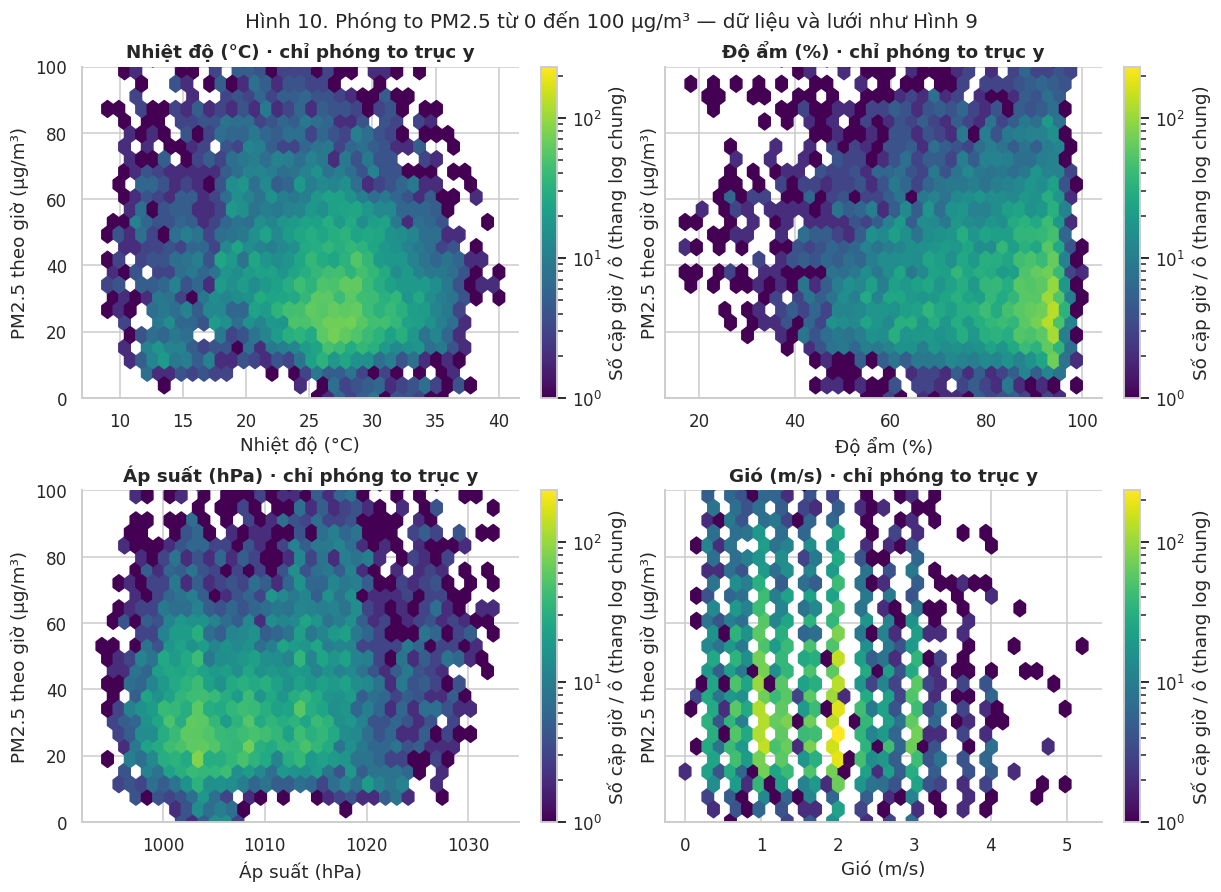

In [21]:
display(dense_hexbin.round(2))
ZOOM_PM25_MAX = 100.0  # Cửa sổ hiển thị, không phải ngưỡng phân loại sức khỏe.
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True, constrained_layout=True)
for ax, weather in zip(axes.flat, WEATHER[:4]):
    pair = hourly[[weather, 'PM25']].dropna()
    artist = ax.hexbin(pair[weather], pair['PM25'], cmap='viridis', norm=hexbin_norm, **hexbin_specs[weather])
    ax.set_ylim(0, ZOOM_PM25_MAX)
    ax.set(xlabel=LABELS[weather], ylabel='PM2.5 theo giờ (µg/m³)', title=f'{LABELS[weather]} · chỉ phóng to trục y')
    fig.colorbar(artist, ax=ax, label='Số cặp giờ / ô (thang log chung)')
fig.suptitle('Hình 10. Phóng to PM2.5 từ 0 đến 100 µg/m³ — dữ liệu và lưới như Hình 9', fontsize=13)
show_figure(fig, 'weather_hexbin_zoom')

**Đọc Hình 10:** đây là cửa sổ phóng to theo trục y của Hình 9, giới hạn hiển thị 0–100 µg/m³. Cùng cặp dữ liệu, lưới, phạm vi x và thang màu được giữ nguyên, không lọc mẫu hay tính lại hệ số tương quan. Các điểm trên 100 vẫn có ở Hình 9. Ô sát biên 100 có thể gom cả điểm ngoài cửa sổ vì lưới được tính trên toàn dữ liệu.

**Vì sao dùng:** các đỉnh rất cao kéo dài trục y khiến vùng đông quan sát bị nén; phóng to giúp xem vùng ấy mà vẫn giữ hình toàn miền để đối chiếu. Không thay thế hình toàn miền bằng hình cắt ngọn. Mốc 100 chỉ là lựa chọn trình bày, không phải ngưỡng an toàn, tiêu chuẩn y tế hay tiêu chí xóa ngoại lệ.

**Giới hạn:** hình phóng to không cho đọc phân bố đuôi cao; quay lại Hình 9 khi đánh giá đỉnh. Số cặp theo màu ở cùng panel có thể đối chiếu giữa hai hình nhờ dùng cùng lưới, nhưng không phải mật độ đã chuẩn hóa theo diện tích hay thước đo tác động thời tiết.

In [22]:
zoom_count = int(pm.le(ZOOM_PM25_MAX).sum())
display(Markdown(f'**Kết quả Hình 10:** có **{zoom_count:,}/{len(pm):,} giờ '
                 f'({100*zoom_count/len(pm):.1f}%)** có PM2.5 ≤ {ZOOM_PM25_MAX:.0f} µg/m³; '
                 f'**{len(pm)-zoom_count:,} giờ** nằm trên cửa sổ này và vẫn được giữ ở Hình 9. '
                 'Vùng tập trung được định vị bằng tâm ô đông nhất: '
                 + '; '.join(f'{w}: thời tiết ≈ {r["Tâm ô — thời tiết"]:.2f}, '
                             f'PM2.5 ≈ {r["Tâm ô — PM2.5 (µg/m³)"]:.2f} µg/m³ '
                             f'({int(r["Số cặp trong ô"])} cặp)' for w,r in dense_hexbin.iterrows())
                 + '. Đơn vị thời tiết theo tên từng biến; các tâm ô chỉ mô tả vùng đông trong lưới đã chọn.'))

**Kết quả Hình 10:** có **8,134/8,785 giờ (92.6%)** có PM2.5 ≤ 100 µg/m³; **651 giờ** nằm trên cửa sổ này và vẫn được giữ ở Hình 9. Vùng tập trung được định vị bằng tâm ô đông nhất: Nhiệt độ (°C): thời tiết ≈ 28.34, PM2.5 ≈ 22.75 µg/m³ (72 cặp); Độ ẩm (%): thời tiết ≈ 94.07, PM2.5 ≈ 26.54 µg/m³ (129 cặp); Áp suất (hPa): thời tiết ≈ 1003.47, PM2.5 ≈ 18.95 µg/m³ (82 cặp); Gió (m/s): thời tiết ≈ 2.01, PM2.5 ≈ 26.54 µg/m³ (232 cặp). Đơn vị thời tiết theo tên từng biến; các tâm ô chỉ mô tả vùng đông trong lưới đã chọn.

### 7.3. Tương quan có thay đổi khi xét riêng từng mùa?

**Vì sao làm:** nếu mùa lạnh cũng là mùa PM2.5 cao, tương quan toàn kỳ có thể gộp khác biệt giữa mùa với liên hệ trong mùa. Tính lại Spearman trong từng mùa giúp phát hiện độ mạnh hoặc chiều liên hệ thay đổi.

Chọn bảng thay vì thêm nhiều đường hồi quy vì cần đọc chính xác từng hệ số và số cặp. Phân nhóm mùa chỉ là đối chiếu mô tả, không kiểm soát hoàn toàn nhiễu, không ước lượng ảnh hưởng độc lập.

In [23]:
season_rows = []
for weather in WEATHER:
    row = {'Biến':LABELS[weather], 'Toàn kỳ':weather_corr.loc[weather, 'Spearman']}
    for season in SEASONS:
        pair = hourly.loc[hourly.Season.eq(season), ['PM25', weather]].dropna()
        row[season] = pair['PM25'].corr(pair[weather], method='spearman')
        row[f'n {season}'] = len(pair)
    season_rows.append(row)
season_corr = pd.DataFrame(season_rows).set_index('Biến')
display(season_corr.round(3))
w = 'Temperature'
display(Markdown(f'**Đối chiếu nhiệt độ:** Spearman toàn kỳ **{weather_corr.loc[w,"Spearman"]:+.3f}**; '
                 + ', '.join(f'{s} **{season_corr.loc[LABELS[w],s]:+.3f}**' for s in SEASONS)
                 + '. Độ mạnh/chiều cần được đọc theo từng nhóm, không mặc định hệ số chung áp dụng trong mọi mùa. '
                 'Bảng vẫn chưa tách được vai trò của gió, áp suất và các biến liên quan khác.'))
opposite_seasons = [s for s in SEASONS if season_corr.loc[LABELS[w], s] * weather_corr.loc[w, 'Spearman'] < 0]
display(Markdown('**Điều cần hiểu:** hệ số trong ' + (', '.join(opposite_seasons) or 'không mùa nào')
                 + ' có dấu ngược với hệ số toàn kỳ. Vì vậy, quan hệ khi gộp các mùa có thể khác quan hệ '
                 'trong mỗi mùa. Dấu đổi chưa có nghĩa quan hệ trong nhóm mạnh hoặc có ý nghĩa thống kê; '
                 'đây là lý do không diễn giải hệ số toàn kỳ thành tác động nhân quả.'))

,Toàn kỳ,Xuân,n Xuân,Hạ,n Hạ,Thu,n Thu,Đông,n Đông
Biến,,,,,,,,,
Nhiệt độ (°C),-0.246,0.253,2161,0.128,2208,0.032,2208,-0.071,2208
Độ ẩm (%),-0.055,-0.031,2161,-0.089,2208,-0.079,2208,-0.036,2208
Áp suất (hPa),0.264,-0.309,2161,-0.260,2208,0.157,2208,0.143,2208
Gió (m/s),-0.150,-0.109,2161,-0.044,2208,-0.133,2208,-0.304,2208
Mưa (mm),-0.197,-0.031,2161,-0.079,2208,-0.136,2208,-0.272,2208


**Đối chiếu nhiệt độ:** Spearman toàn kỳ **-0.246**; Xuân **+0.253**, Hạ **+0.128**, Thu **+0.032**, Đông **-0.071**. Độ mạnh/chiều cần được đọc theo từng nhóm, không mặc định hệ số chung áp dụng trong mọi mùa. Bảng vẫn chưa tách được vai trò của gió, áp suất và các biến liên quan khác.

**Điều cần hiểu:** hệ số trong Xuân, Hạ, Thu có dấu ngược với hệ số toàn kỳ. Vì vậy, quan hệ khi gộp các mùa có thể khác quan hệ trong mỗi mùa. Dấu đổi chưa có nghĩa quan hệ trong nhóm mạnh hoặc có ý nghĩa thống kê; đây là lý do không diễn giải hệ số toàn kỳ thành tác động nhân quả.

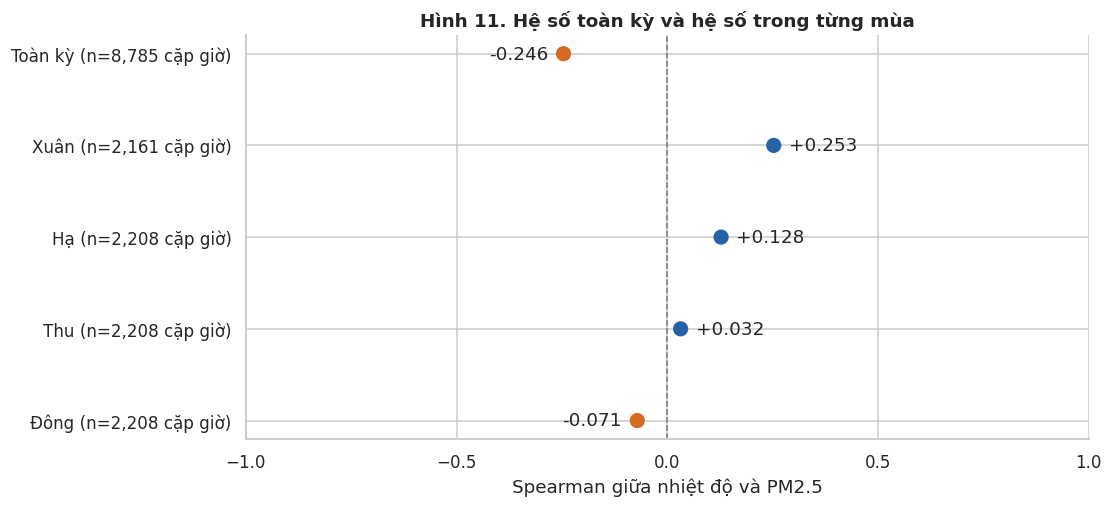

In [24]:
temp_groups = ['Toàn kỳ'] + SEASONS
temp_values = np.array([weather_corr.loc['Temperature', 'Spearman']] +
                       [season_corr.loc[LABELS['Temperature'], s] for s in SEASONS])
temp_counts = [int(weather_corr.loc['Temperature', 'Số cặp giờ'])] +               [int(season_corr.loc[LABELS['Temperature'], f'n {s}']) for s in SEASONS]
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
positions = np.arange(len(temp_groups))
ax.axvline(0, color='#777777', linestyle='--', linewidth=1)
ax.scatter(temp_values, positions, c=[BLUE if v >= 0 else ORANGE for v in temp_values], s=80, zorder=3)
for y, value in zip(positions, temp_values):
    ax.annotate(f'{value:+.3f}', (value, y), xytext=(10 if value >= 0 else -10, 0),
                textcoords='offset points', va='center', ha='left' if value >= 0 else 'right')
ax.set_yticks(positions, [f'{g} (n={n:,} cặp giờ)' for g,n in zip(temp_groups,temp_counts)])
ax.set(xlim=(-1, 1), xticks=[-1,-.5,0,.5,1], xlabel='Spearman giữa nhiệt độ và PM2.5',
       title='Hình 11. Hệ số toàn kỳ và hệ số trong từng mùa')
ax.invert_yaxis()
show_figure(fig, 'temperature_correlation_by_season')

**Đọc Hình 11:** mỗi chấm là một hệ số Spearman nhiệt độ–PM2.5 của nhóm ghi ở trục dọc; `n` là số cặp cùng giờ hợp lệ. Chấm bên trái 0 là liên hệ âm, bên phải là dương. Trục ngang giữ nguyên toàn thang −1 đến +1 để không phóng đại chênh lệch nhỏ. Các chấm không có khoảng tin cậy; màu chỉ phân biệt dấu, không thể hiện ý nghĩa thống kê.

**Vì sao dùng:** biểu đồ chấm giúp thấy hệ số đổi chiều dễ hơn đọc bảng nhiều cột; bảng gốc vẫn giữ để xem các biến khác. Không nối các mùa bằng một đường vì đây là nhóm phân loại, không phải diễn biến của cùng một hệ số theo thời gian. Chưa vẽ đường hồi quy chung rồi coi là quy luật trong mọi mùa.

**Ý nghĩa:** khi gộp mùa, hệ số vừa phản ánh khác biệt giữa mùa vừa phản ánh sự biến động trong mùa. Vì thế toàn kỳ có thể âm trong khi một số mùa dương. Đây là dấu hiệu cần thận trọng với cách gộp dữ liệu, không đủ để khẳng định đã xác định chính xác cơ chế tạo ra khác biệt.

**Giới hạn:** phân nhóm theo mùa chưa kiểm soát áp suất, độ ẩm, gió hoặc nguồn thải. Không suy từ tương quan rằng điều chỉnh nhiệt độ sẽ gây ra mức thay đổi PM2.5 tương ứng; không so sánh ý nghĩa thống kê chỉ bằng dấu hoặc độ lớn của chấm.

In [25]:
display(Markdown(f'**Kết quả Hình 11:** hệ số toàn kỳ **{temp_values[0]:+.3f}**, '
                 f'trong Xuân **{temp_values[1]:+.3f}**, Hạ **{temp_values[2]:+.3f}**, '
                 f'Thu **{temp_values[3]:+.3f}**, Đông **{temp_values[4]:+.3f}**. '
                 'Do đó câu “trời càng lạnh thì PM2.5 càng cao” không mô tả nhất quán mọi mùa của mẫu này. '
                 'Các hệ số gần 0 trong nhóm cũng không chứng minh mọi kiểu liên hệ đều không tồn tại.'))

**Kết quả Hình 11:** hệ số toàn kỳ **-0.246**, trong Xuân **+0.253**, Hạ **+0.128**, Thu **+0.032**, Đông **-0.071**. Do đó câu “trời càng lạnh thì PM2.5 càng cao” không mô tả nhất quán mọi mùa của mẫu này. Các hệ số gần 0 trong nhóm cũng không chứng minh mọi kiểu liên hệ đều không tồn tại.

### 7.4. Giờ có mưa và không mưa khác nhau thế nào?

Chia thành `Precipitation > 0` và `Precipitation = 0`, chỉ dùng các giờ có cả PM2.5 và lượng mưa. Đây là so sánh hai nhóm quan sát, không phải thử nghiệm trước/sau một đợt mưa.

,n,mean,median,q1,q3
Nhóm,,,,,
Không mưa,7051,53.11,39.0,26.0,59.0
Có mưa,1734,34.31,30.0,20.0,42.0


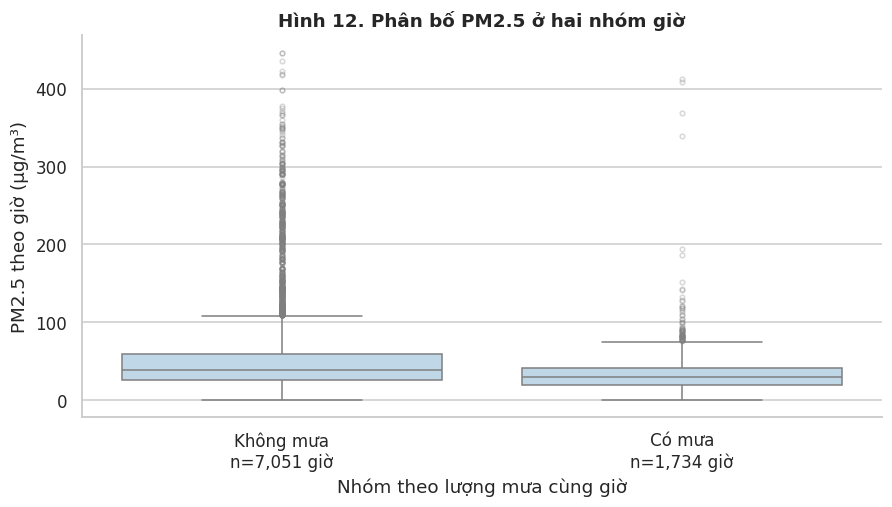

In [26]:
rain_pairs = hourly[['PM25', 'Precipitation']].dropna().copy()
rain_pairs['Nhóm'] = np.where(rain_pairs.Precipitation.gt(0), 'Có mưa', 'Không mưa')
rain_order = ['Không mưa', 'Có mưa']
rain_summary = rain_pairs.groupby('Nhóm')['PM25'].agg(n='count', mean='mean', median='median',
                          q1=lambda s:s.quantile(.25), q3=lambda s:s.quantile(.75)).reindex(rain_order)
display(rain_summary.round(2))
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
sns.boxplot(data=rain_pairs, x='Nhóm', y='PM25', order=rain_order, color='#b8d8ee', ax=ax,
            flierprops={'markersize':3, 'alpha':.3})
ax.set_xticks(range(2), [f'{g}{chr(10)}n={int(rain_summary.loc[g,"n"]):,} giờ' for g in rain_order])
ax.set(xlabel='Nhóm theo lượng mưa cùng giờ', ylabel='PM2.5 theo giờ (µg/m³)', title='Hình 12. Phân bố PM2.5 ở hai nhóm giờ')
show_figure(fig, '09_rain_groups')

**Đọc Hình 12:** hộp và đường giữa lần lượt thể hiện Q1–Q3 và median PM2.5 của mỗi nhóm giờ; `n` là cỡ mẫu. Quy tắc râu giống Hình 1. Điểm cao được giữ lại.

**Vì sao dùng:** lượng mưa có nhiều số 0, nên so hai nhóm là cách dễ hiểu để bổ sung cho một hệ số tương quan mưa–PM2.5. Boxplot cho biết biến động và sự chồng lấn mà hai cột mean không thể hiện. Chưa chia mưa thành nhiều mức tùy ý vì sẽ làm phân tán mẫu và cần biện minh ngưỡng.

**Giới hạn:** nhóm mưa/không mưa có thể khác về mùa, nhiệt độ, giờ trong ngày. Chênh lệch quan sát không chứng minh mưa gây ra thay đổi PM2.5; không suy thành hiệu quả làm sạch sau một cơn mưa từ các cặp cùng giờ này.

In [27]:
rain_diff = rain_summary.loc['Có mưa', 'median'] - rain_summary.loc['Không mưa', 'median']
display(Markdown(f'**Kết quả Hình 12:** median nhóm có mưa **{rain_summary.loc["Có mưa","median"]:.2f}**, '
                 f'nhóm không mưa **{rain_summary.loc["Không mưa","median"]:.2f} µg/m³**; '
                 f'chênh có mưa trừ không mưa **{rain_diff:+.2f} µg/m³**. '
                 f'Có mưa chiếm **{100*rain_summary.loc["Có mưa","n"]/len(rain_pairs):.1f}%** số cặp hợp lệ. '
                 'Đọc chênh lệch này cùng độ chồng lấn hộp và các giới hạn đã nêu.'))

**Kết quả Hình 12:** median nhóm có mưa **30.00**, nhóm không mưa **39.00 µg/m³**; chênh có mưa trừ không mưa **-9.00 µg/m³**. Có mưa chiếm **19.7%** số cặp hợp lệ. Đọc chênh lệch này cùng độ chồng lấn hộp và các giới hạn đã nêu.

## 8. Tổng hợp: Part 2 đã tạo ra điều gì?

Đầu ra là bảng kiểm tra dữ liệu, các bảng thống kê và **12 hình** trả lời bốn câu hỏi. Bảng giờ/ngày là dữ liệu trung gian trong bộ nhớ; CSV gốc giữ nguyên. Các số dưới đây được tính từ chính lần chạy notebook, không chép từ kết luận cũ.

In [28]:
display(Markdown(f'''
1. **Phân bố — Hình 1:** PM2.5 theo giờ có mean **{pm.mean():.2f}**, median **{median:.2f} µg/m³**, P95 **{pm.quantile(.95):.2f}**. Đọc mean cùng median và đuôi phân bố để không chỉ nhìn một mức trung bình.
2. **Theo ngày — Hình 2:** sau lọc còn **{len(daily)} ngày đầy đủ**; ngày mean cao nhất **{peak_day:%d/%m/%Y}**, **{daily.loc[peak_day,'pm25_mean']:.2f} µg/m³**. Ngày thiếu giờ không được coi ngang với ngày đủ giờ.
3. **Theo mùa — Hình 5:** mean ngày của **{high_season}** là **{season_daily.loc[high_season,'mean']:.2f}**, của **{low_season}** là **{season_daily.loc[low_season,'mean']:.2f} µg/m³**. Sự khác biệt này mô tả giai đoạn đã quan sát, không chứng minh quy luật mọi năm.
4. **Theo giờ — Hình 6–7:** mean gộp cao nhất **{peak_hour}h**, thấp nhất **{low_hour}h**; giờ có median cao nhất theo tháng nằm ở **{month_peaks.nunique()} vị trí khác nhau**. Quy luật gộp không đại diện cho mọi tháng/ngày.
5. **Thời tiết — Hình 8–11 và bảng theo mùa:** biến có |Spearman| toàn kỳ lớn nhất trong tập đã chọn là **{LABELS[strongest]}** (**{weather_corr.loc[strongest,'Spearman']:+.3f}**). Riêng nhiệt độ có hệ số toàn kỳ **{weather_corr.loc['Temperature','Spearman']:+.3f}**, trong mùa xuân là **{season_corr.loc[LABELS['Temperature'],'Xuân']:+.3f}**: quan hệ gộp và trong mùa có thể khác chiều. Đây chưa phải ảnh hưởng độc lập hay bằng chứng nhân quả.
6. **Mưa — Hình 12:** median có mưa trừ không mưa là **{rain_diff:+.2f} µg/m³**. Hai nhóm không được ghép tương đồng về mùa và điều kiện khác, nên chưa thể quy chênh lệch cho mưa.
'''))


1. **Phân bố — Hình 1:** PM2.5 theo giờ có mean **49.40**, median **36.00 µg/m³**, P95 **129.57**. Đọc mean cùng median và đuôi phân bố để không chỉ nhìn một mức trung bình.
2. **Theo ngày — Hình 2:** sau lọc còn **366 ngày đầy đủ**; ngày mean cao nhất **29/11/2023**, **261.01 µg/m³**. Ngày thiếu giờ không được coi ngang với ngày đủ giờ.
3. **Theo mùa — Hình 5:** mean ngày của **Đông** là **83.86**, của **Hạ** là **30.81 µg/m³**. Sự khác biệt này mô tả giai đoạn đã quan sát, không chứng minh quy luật mọi năm.
4. **Theo giờ — Hình 6–7:** mean gộp cao nhất **20h**, thấp nhất **16h**; giờ có median cao nhất theo tháng nằm ở **9 vị trí khác nhau**. Quy luật gộp không đại diện cho mọi tháng/ngày.
5. **Thời tiết — Hình 8–11 và bảng theo mùa:** biến có |Spearman| toàn kỳ lớn nhất trong tập đã chọn là **Áp suất (hPa)** (**+0.264**). Riêng nhiệt độ có hệ số toàn kỳ **-0.246**, trong mùa xuân là **+0.253**: quan hệ gộp và trong mùa có thể khác chiều. Đây chưa phải ảnh hưởng độc lập hay bằng chứng nhân quả.
6. **Mưa — Hình 12:** median có mưa trừ không mưa là **-9.00 µg/m³**. Hai nhóm không được ghép tương đồng về mùa và điều kiện khác, nên chưa thể quy chênh lệch cho mưa.


### Giới hạn và hướng chuyển sang phần sau

- Chỉ có khoảng một năm, với hai tháng biên không trọn vẹn; không suy ra xu thế nhiều năm. Số giờ/ngày từng nhóm đã được báo để đọc cùng thống kê.
- Dữ liệu đại diện vị trí Hà Nội do API cung cấp; CSV không có đủ thông tin trạm/quận để so sánh không gian hoặc kiểm chứng độ bao phủ toàn thành phố.
- Các giờ liền nhau có thể phụ thuộc; hàng nghìn giờ không tương đương hàng nghìn mẫu độc lập. Bài không đưa ra kiểm định nhân quả hoặc p-value ngây thơ trên các giờ.
- Tương quan toàn kỳ và theo mùa là mô tả. Không có lưu lượng giao thông, nguồn thải hay thiết kế nghiên cứu để khẳng định nguyên nhân.
- Không xác nhận phân loại sức khỏe theo các ngưỡng cũ, không quy AQI về PM2.5 và không coi dữ liệu lịch sử là tình trạng hiện tại.
- EDA đã chỉ ra các khoảng biến động và quy tắc ngày đủ giờ có thể dùng khi thiết kế Part 3. Nếu làm dự báo, phải chia dữ liệu theo thời gian và chỉ chọn đặc trưng từ thông tin sẵn có tại lúc dự báo. Phần tiếp theo ở [Part 3 của Dương](Part%203%20-%20ARIMA.ipynb), dùng cùng quy tắc ngày đủ giờ.

### Chạy lại

Chọn kernel Python đã cài các thư viện ở `Duong/requirements.txt`, mở từ thư mục gốc và **Restart Kernel → Run All**. Notebook chỉ đọc CSV, lưu ảnh và bảng kiểm chứng JSON vào `Duong/outputs/part2/`. Các lời giải thích có số liệu được tạo khi chạy; nếu thay dữ liệu cần đọc lại cả diễn giải định tính và các kiểm tra chất lượng.

In [29]:
# Kiểm tra tính nhất quán giữa các phép tổng hợp, không chỉ kiểm tra code chạy được.
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing
assert daily['rows'].eq(24).all() and daily['valid_pm25'].eq(24).all()
assert len(daily) + len(excluded_days) == len(daily_audit)
assert monthly['n'].sum() == len(daily)
assert by_hour['n'].sum() == pm.size
assert heat_count.to_numpy().sum() == pm.size
assert rain_summary['n'].sum() == len(rain_pairs)
assert (rolling7.notna() == daily_calendar.notna().rolling(7, min_periods=7).sum().eq(7)).all()
assert aqi_complete.sum() == aqi_daily.notna().sum()
assert weather_counts['Precipitation'].sum() == hourly['Precipitation'].notna().sum()
assert np.allclose(temp_values[1:], season_corr.loc[LABELS['Temperature'], SEASONS].to_numpy(dtype=float))
assert all(int(a.get_array().sum()) == len(hourly[['PM25', w]].dropna()) for a,w in zip(hexbin_artists, WEATHER[:4]))
verification = {
    'hourly_rows':len(hourly), 'daily_full_days':len(daily),
    'excluded_days':excluded_days.index.strftime('%Y-%m-%d').tolist(),
    'missing_timestamps':len(absent_hours), 'mean_pm25':float(pm.mean()),
    'median_pm25':float(median), 'p95_pm25':float(pm.quantile(.95)),
    'peak_daily_date':str(peak_day.date()), 'peak_daily_mean':float(daily.loc[peak_day,'pm25_mean']),
    'peak_mean_hour':peak_hour, 'low_mean_hour':low_hour,
    'season_daily':json.loads(season_daily.to_json(orient='index')),
    'weather_correlations':json.loads(weather_corr.to_json(orient='index')),
    'rain_groups':json.loads(rain_summary.to_json(orient='index')),
    'aqi_max':aqi_peak_value, 'aqi_max_first_at':str(aqi_peak_time),
    'aqi_complete_days':int(aqi_complete.sum()),
    'season_weather':json.loads(season_weather.to_json(orient='index')),
    'temperature_spearman_by_group':dict(zip(temp_groups, map(float,temp_values))),
    'hexbin_zoom_upper_pm25':ZOOM_PM25_MAX, 'hexbin_zoom_hours':zoom_count,
    'figures':12, 'consistency_checks':'passed',
}
(OUT / 'verification.json').write_text(json.dumps(verification, ensure_ascii=False, indent=2), encoding='utf-8')
print('Kiểm tra tổng hợp: đạt. Kết quả và ảnh được lưu tại Duong/outputs/part2/.')

Kiểm tra tổng hợp: đạt. Kết quả và ảnh được lưu tại Duong/outputs/part2/.
